# Blast Pipeline
***

# NCBI pre-data wranglin'
***

plasmids = {strain : [{ NCBI_ID : {plasmid : seq}}, plasmid_matrix]}
class plasmid:
    plasmids_present = {plasmid1: (yes/no), plasmid2: (yes/no), ...}

- ok so first I need to get all of the strains set aside in their own little group.
- then I need to get all of the plasmids present for each strain in their group
- then I need to identify which are present and then set those into the data object
- then use that to identify which strain is present based on construction of a new object given strain assignment.

- something like
```
for contig1:
    top_hit = hit1
    top_hit.score = hit1.score
    top_hit.ID = hit1.ID
    top_hit.length = hit1.length
    top_hit.percentIdent = hit1.percentIdent
    # or some iteration of this.
    # then take and parse out the top hit, or rather
    # look through all hits and then parse the ID given by blast to determine which plasmid it says it is. 
    # then use the score, length, percent ident, etc to assign some score to the hit
    # then use all of the scores to assign probability and then use to determine plasmid assignment
    # then after that, use all of the plasmid assignment values to determine strain identification
    # would likely need a probability matrix for each strain given the plasmids present..........
```

In [1]:
import glob
import csv
import pandas
import pprint
import csv
import re
import json
import os
import tqdm
import pickle

In [2]:
# literally never used this function lol
def read_fasta(file_name):
    sequences = {}
    F = open(file_name)
    for line in F:
        if line[0] == '>':
            defline = line.strip()
            defline = defline.replace('>','')
            terms = defline.split()
            seqname = terms[0]
        else:
            if seqname not in sequences:
                sequences[seqname] = list()
            sequences[seqname].append(line.strip())
    for seqname in sequences:
        seq = ''.join(sequences[seqname])
        sequences[seqname] = seq
    return(sequences)

In [3]:
working_directory = '/Users/mf019/bioinformatics/blastDB/BbPlasmid/plasmid_seqs/fresh_attempt/'
input_fastas = working_directory+'NCBI_sequences/ncbi_dataset/data/'
output_dir = working_directory+'output/'
excel_files =output_dir+'excel/'
output_tsv = output_dir+'tsv/'
output_json = output_dir+'json/'
output_plots = output_dir+'plots/'
output_pickles = output_dir+'the_cannery/'

In [4]:
print('working directory: ', working_directory)
#print(os.listdir(path=working_directory))
print('input fastas: ', input_fastas)
#print(os.listdir(path=input_fastas))
print('output directory: ', output_dir)
#print(os.listdir(path=output_dir))
print('excel_files', excel_files)
#print(os.listdir(excel_files))
print('TSV output: ', output_tsv)
#print(os.listdir(path=output_tsv))
print('JSON output: ', output_json)
#print(os.listdir(path=output_json))
print('Plots output: ', output_plots)
#print(os.listdir(path=output_plots))
print('Pickles output: ', output_pickles)
#print(os.listdir(path=output_pickles))


working directory:  /Users/mf019/bioinformatics/blastDB/BbPlasmid/plasmid_seqs/fresh_attempt/
input fastas:  /Users/mf019/bioinformatics/blastDB/BbPlasmid/plasmid_seqs/fresh_attempt/NCBI_sequences/ncbi_dataset/data/
output directory:  /Users/mf019/bioinformatics/blastDB/BbPlasmid/plasmid_seqs/fresh_attempt/output/
excel_files /Users/mf019/bioinformatics/blastDB/BbPlasmid/plasmid_seqs/fresh_attempt/output/excel/
TSV output:  /Users/mf019/bioinformatics/blastDB/BbPlasmid/plasmid_seqs/fresh_attempt/output/tsv/
JSON output:  /Users/mf019/bioinformatics/blastDB/BbPlasmid/plasmid_seqs/fresh_attempt/output/json/
Plots output:  /Users/mf019/bioinformatics/blastDB/BbPlasmid/plasmid_seqs/fresh_attempt/output/plots/
Pickles output:  /Users/mf019/bioinformatics/blastDB/BbPlasmid/plasmid_seqs/fresh_attempt/output/the_cannery/


In [5]:
os.chdir(path=working_directory)

In [6]:
genomes = glob.glob('**/*.fna', recursive=True)
print("number of genomes present: ",len(genomes))

number of genomes present:  33


Okay, so actually, the PAli genome was messed up because none of the headers for the plasmids had the strain ID in them. 
a quick sed script fixed it. 

```
cat Bb_all_genomes/ncbi_dataset/data/GCA_002151465.1/GCA_002151465.1_ASM215146v1_genomic.fna | grep ">"
>CP019844.1 Borreliella burgdorferi strain PAli, complete sequence
>CP019851.1 Borreliella burgdorferi plasmid lp17, complete sequence
>CP019845.1 Borreliella burgdorferi plasmid cp26, complete sequence
>CP019846.1 Borreliella burgdorferi plasmid cp32-1, complete sequence
>CP019847.1 Borreliella burgdorferi plasmid cp32-3, complete sequence
>CP019848.1 Borreliella burgdorferi plasmid cp32-4, complete sequence
>CP019849.1 Borreliella burgdorferi plasmid cp32-5, complete sequence
>CP019850.1 Borreliella burgdorferi plasmid cp32-9, complete sequence
>CP019852.1 Borreliella burgdorferi plasmid lp36, complete sequence
>CP019853.1 Borreliella burgdorferi plasmid lp38, complete sequence
>CP019854.1 Borreliella burgdorferi plasmid lp54, complete sequence
>CP019855.1 Borreliella burgdorferi plasmid lp56, complete sequence
```
ok lets fix it with sed
```
cat Bb_all_genomes/ncbi_dataset/data/GCA_002151465.1/GCA_002151465.1_ASM215146v1_genomic.fna|sed 's/Borreliella burgdorferi plasmid/Borreliella burgdorferi strain PAli plasmid/g' | > Bb_all_genomes/ncbi_dataset/data/GCA_002151465.1/GCA_002151465.1_ASM215146v1_genomic.fna.fixed
```
ok so lets check the fixed headers
```
cat Bb_all_genomes/ncbi_dataset/data/GCA_002151465.1/GCA_002151465.1_ASM215146v1_genomic.fna.fixed|grep ">"
>CP019844.1 Borreliella burgdorferi strain PAli, complete sequence
>CP019851.1 Borreliella burgdorferi strain PAli plasmid lp17, complete sequence
>CP019845.1 Borreliella burgdorferi strain PAli plasmid cp26, complete sequence
>CP019846.1 Borreliella burgdorferi strain PAli plasmid cp32-1, complete sequence
>CP019847.1 Borreliella burgdorferi strain PAli plasmid cp32-3, complete sequence
>CP019848.1 Borreliella burgdorferi strain PAli plasmid cp32-4, complete sequence
>CP019849.1 Borreliella burgdorferi strain PAli plasmid cp32-5, complete sequence
>CP019850.1 Borreliella burgdorferi strain PAli plasmid cp32-9, complete sequence
>CP019852.1 Borreliella burgdorferi strain PAli plasmid lp36, complete sequence
>CP019853.1 Borreliella burgdorferi strain PAli plasmid lp38, complete sequence
>CP019854.1 Borreliella burgdorferi strain PAli plasmid lp54, complete sequence
>CP019855.1 Borreliella burgdorferi strain PAli plasmid lp56, complete sequence
```
ok so now just rename the fixed file to the original file
```
mv Bb_all_genomes/ncbi_dataset/data/GCA_002151465.1/GCA_002151465.1_ASM215146v1_genomic.fna.fixed Bb_all_genomes/ncbi_dataset/data/GCA_002151465.1/GCA_002151465.1_ASM215146v1_genomic.fna


```

# actually wrangle the NCBI data now.
 this is messy but this works

In [7]:

plasmid_dict = {}
id2plasmid = {}
plasmid_list = []
header = ['ID', 'Plasmid', 'Strain']

i = 0
with open(output_tsv+'acc_to_plasmid.tsv', 'w', newline='') as tsvfile:
    writer = csv.writer(tsvfile, delimiter='\t', lineterminator='\n')
    writer.writerow(header)
    for filename in genomes:
        print(filename)
        for line in open(file=filename):
            syntheticVector = False
            if line.startswith(">"):
                seq = []
                header = line.strip(">").replace(",","")
                filter_1  = re.findall("whole genome shotgun sequence", header)
                if filter_1 == []:
                    # regex madness to tidy up the plasmid IDs 
                    pattern = r'.*?([cl]?p\d+(?:-?_?\+?\d+(?:-?_?\+?\d+)?)?(?!\w))' # ok this is a bit tricky but this is what I need.
                    matches = re.findall(pattern, header)
                    #print(header, 'matches: ',matches)
                    if matches == []:
                        title_hit = re.findall('pBSV2', header) # this is sloppy and probably broken
                        if title_hit == []:
                            plasmidID = 'chromosome'
                        else:
                            plasmidID = ' '.join(title_hit) # this is hideous I'm sorry
                            NCBI_ID = 'pBSV2_2'
                            strainID = 'Synthetic_Vector'
                            syntheticVector = True
                    else:
                        plasmidID = ' '.join(matches)
                    if syntheticVector is not True:
                        plasmidID = plasmidID.replace("_","-").replace(" ","-")
                        #print(plasmidID, '\n')
                        header = header.split(' ')
                        NCBI_ID = header[0]

                        if header[3] == 'strain':
                            strainID = header[4]
                            #plasmidID = header[6]

                        else:
                            if header[3] == header[5]: # some of these fields are wonky
                                strainID = header[3]
                                #plasmidID = header[6]
                            else:
                                strainID = header[3]
                                #plasmidID = header[5]

                        if strainID == ('plasmid' or 'strain' or 'isolate' or 'linear' or 'circular'):
                            print("something is wrong with this line!!!!!!!")
                            print(header)
                            print("!!!!!")
                        else:
                            if plasmidID not in plasmid_list:
                                plasmid_list.append(plasmidID)
                            writer.writerow([NCBI_ID, plasmidID, strainID])
                            if strainID not in plasmid_dict:
                                plasmid_dict[strainID] = []
                                #print("making new key")
                                plasmid_dict[strainID].append(plasmidID)
                                #print("appending")
                                #print(i)
                                i += 1
                            else:
                                plasmid_dict[strainID].append(plasmidID)
                                # print("appending")
                                # print(i)
                                i += 1
                            if NCBI_ID not in id2plasmid:
                                id2plasmid[NCBI_ID] = {}
                                id2plasmid[NCBI_ID] = {'name' : plasmidID,'strain' :strainID}
                            else:
                                print("DUPE NCBI ID DETECTED!!! BAD BAD BAD ")
                    else:
                        if plasmidID not in plasmid_list:
                            plasmid_list.append(plasmidID)
                            writer.writerow([NCBI_ID, plasmidID, strainID])
                            if strainID not in plasmid_dict:
                                plasmid_dict[strainID] = []
                                #print("making new key")
                                plasmid_dict[strainID].append(plasmidID)
                                #print("appending")
                                #print(i)
                                i += 1
                            else:
                                plasmid_dict[strainID].append(plasmidID)
                                # print("appending")
                                # print(i)
                                i += 1
                            if NCBI_ID not in id2plasmid:
                                id2plasmid[NCBI_ID] = {}
                                id2plasmid[NCBI_ID] = {'name' : plasmidID,'strain' :strainID}
                        
                else:
                    pass
        print("Successfully Parsed Plasmids and Headers!")



NCBI_sequences/ncbi_dataset/data/GCA_030445005.1/GCA_030445005.1_ASM3044500v1_genomic.fna
Successfully Parsed Plasmids and Headers!
NCBI_sequences/ncbi_dataset/data/GCA_002151465.1/GCA_002151465.1_ASM215146v1_genomic.fna
Successfully Parsed Plasmids and Headers!
NCBI_sequences/ncbi_dataset/data/GCA_024733895.1/GCA_024733895.1_ASM2473389v1_genomic.fna
Successfully Parsed Plasmids and Headers!
NCBI_sequences/ncbi_dataset/data/GCA_000166655.2/GCA_000166655.2_ASM16665v1_genomic.fna
Successfully Parsed Plasmids and Headers!
NCBI_sequences/ncbi_dataset/data/GCA_024733995.1/GCA_024733995.1_ASM2473399v1_genomic.fna
Successfully Parsed Plasmids and Headers!
NCBI_sequences/ncbi_dataset/data/GCA_024662195.1/GCA_024662195.1_ASM2466219v1_genomic.fna
Successfully Parsed Plasmids and Headers!
NCBI_sequences/ncbi_dataset/data/GCA_003367295.1/GCA_003367295.1_ASM336729v1_genomic.fna
Successfully Parsed Plasmids and Headers!
NCBI_sequences/ncbi_dataset/data/GCA_030439605.1/GCA_030439605.1_ASM3043960v1_ge

In [8]:
another_plasmid_dict = {}
plasmid_list = []
new_key_count = 1
total_plasmid_count = 1


for key in plasmid_dict:
    lvl0 = plasmid_dict[key]
    for item in lvl0:
        plasmid = str(item).strip("\{\}\'")
        #print(plasmid)
        plasmid_list.append(plasmid)
        #print(header, 'matches: ',matches)
        if matches == []:
            plasmidID = 'chromosome'
        else:
            plasmidID = ' '.join(matches)
        if plasmid not in another_plasmid_dict:
            another_plasmid_dict[plasmid] = []
            new_key_count += 1
            another_plasmid_dict[plasmid].append(key)
            total_plasmid_count += 1
        else:
            another_plasmid_dict[plasmid].append(key)
            total_plasmid_count += 1
print("total plasmids: ", new_key_count)
print("total_plasmid_count: ", total_plasmid_count)

total plasmids:  68
total_plasmid_count:  319


# The below code block is required to convert the unstandardized names to be able to compile a matrix correctly.

Since for several NCBI genomes, there is no indication as to whether or not a plasmid is linear or circular, it is the same plasmid number but without c or l. I have used some deduction to create a mapping dictionary to condense these values down. 

In [9]:
rename_dict = {}
for k in plasmid_dict:
    for v in plasmid_dict[k]:        
        if v[1::] in plasmid_list:
            if v[1::] not in rename_dict:
                rename_dict[v[1::]] = v
                print("added key ->", v[1::],":",v)
            else:
                pass

for key in plasmid_dict:
    strain = plasmid_dict[key]
    for iter in enumerate(strain):
        if strain[iter[0]] in rename_dict:
            print(iter[0],iter[1])
            strain[iter[0]] = rename_dict[iter[1]]
            print(strain[iter[0]])
        else:
            pass
            

added key -> p17 : lp17
added key -> p26 : cp26
added key -> p54 : lp54
added key -> p32-1 : cp32-1
added key -> p32-3 : cp32-3
added key -> p32-4 : cp32-4
added key -> p32-5 : cp32-5
added key -> p32-9 : cp32-9
added key -> p36 : lp36
added key -> p38 : lp38
added key -> p56 : lp56
added key -> p32-11 : cp32-11
added key -> p32-12 : cp32-12
added key -> p32-6 : cp32-6
added key -> p32-8 : cp32-8
added key -> p25 : lp25
added key -> p28-1 : lp28-1
added key -> p28-3 : lp28-3
added key -> p28-4 : lp28-4
added key -> p28-5 : lp28-5
added key -> p28-6 : lp28-6
added key -> p9 : cp9
added key -> p32-7 : cp32-7
added key -> p32-2 : cp32-2
added key -> p28-2 : lp28-2
added key -> p21 : lp21
1 p9
cp9
2 p17
lp17
3 p21
lp21
4 p25
lp25
5 p26
cp26
6 p28-1
lp28-1
7 p28-2
lp28-2
8 p28-3
lp28-3
9 p28-4
lp28-4
10 p32-1
cp32-1
11 p32-3
cp32-3
12 p32-4
cp32-4
13 p32-6
cp32-6
14 p32-7
cp32-7
15 p32-8
cp32-8
16 p32-9
cp32-9
17 p36
lp36
18 p38
lp38
19 p54
lp54
20 p56
lp56
1 p17
lp17
2 p26
cp26
3 p28-3
lp2

In [10]:
# rename bad plasmids in plasmid list
for i in enumerate(plasmid_list):
    if i[1] in rename_dict:
        print(i)
        plasmid_list[i[0]]=rename_dict[i[1]]

(38, 'p9')
(39, 'p17')
(40, 'p21')
(41, 'p25')
(42, 'p26')
(43, 'p28-1')
(44, 'p28-2')
(45, 'p28-3')
(46, 'p28-4')
(47, 'p32-1')
(48, 'p32-3')
(49, 'p32-4')
(50, 'p32-6')
(51, 'p32-7')
(52, 'p32-8')
(53, 'p32-9')
(54, 'p36')
(55, 'p38')
(56, 'p54')
(57, 'p56')
(159, 'p17')
(160, 'p26')
(161, 'p28-3')
(162, 'p28-4')
(163, 'p28-5')
(164, 'p28-6')
(165, 'p32-11')
(166, 'p32-12')
(167, 'p32-2')
(168, 'p32-3')
(169, 'p32-5')
(170, 'p32-6')
(171, 'p32-7')
(172, 'p32-9')
(173, 'p36')
(174, 'p38')
(175, 'p54')
(190, 'p17')
(191, 'p25')
(192, 'p26')
(193, 'p28-1')
(194, 'p28-3')
(195, 'p28-4')
(196, 'p28-6')
(197, 'p32-1')
(198, 'p32-3')
(199, 'p32-5')
(200, 'p32-6')
(201, 'p32-7')
(202, 'p32-8')
(203, 'p36')
(204, 'p38')
(205, 'p54')
(206, 'p56')


In [11]:
for ID in id2plasmid:
    strain = id2plasmid[ID]
    name = strain['name']
    if name in rename_dict:
        #print(ID)
        #print("old name:"+name)
        #print(name+"="+rename_dict[name])
        id2plasmid[ID]['name'] = rename_dict[name]
        #print("New name:"+name)
    else:
        pass

In [12]:
#for k in id2plasmid:
#    print(id2plasmid[k])

# Now lets make the structures required to generate a matrix

In [13]:
print(len(plasmid_dict))
pprint.pprint(plasmid_dict)

27
{'156a': ['cp26',
          'cp32-1',
          'cp32-11',
          'cp32-12',
          'cp32-3',
          'cp32-4',
          'cp32-6',
          'cp32-7',
          'cp32-8',
          'lp17',
          'lp25',
          'lp28-1',
          'lp28-3',
          'lp28-4',
          'lp28-5',
          'lp28-6',
          'lp36',
          'lp38',
          'lp54'],
 '80a': ['chromosome', 'lp17', 'cp26', 'lp54'],
 '94a': ['cp26',
         'cp32-10',
         'cp32-11',
         'cp32-5',
         'cp32-6',
         'cp32-7',
         'cp9',
         'lp17',
         'lp28-3',
         'lp28-4',
         'lp36',
         'lp54',
         'lp56'],
 'Am293': ['chromosome', 'lp17', 'cp26', 'lp54'],
 'Am315': ['chromosome', 'lp17', 'cp26', 'lp54'],
 'Am388': ['chromosome', 'lp17', 'cp26', 'lp54'],
 'B31': ['chromosome',
         'lp5',
         'cp9',
         'lp17',
         'lp21',
         'lp25',
         'cp26',
         'lp28-1',
         'lp28-2',
         'lp28-3',
         'l

In [14]:
header = ['ID', 'Plasmid', 'Strain']

i = 0
with open(output_tsv+'acc_to_plasmid.tsv', 'w', newline='') as tsvfile:
    writer = csv.writer(tsvfile, delimiter='\t', lineterminator='\n')
    writer.writerow(header)
    for key in id2plasmid:
        NCBI_ID = key
        plasmidID = id2plasmid[key]['name']
        strainID = id2plasmid[key]['strain']
        print(NCBI_ID,plasmidID,strainID)
        writer.writerow([NCBI_ID, plasmidID, strainID])
        print("Line Written!")

CP124100.1 chromosome NE_5261
Line Written!
CP124098.1 lp17 NE_5261
Line Written!
CP124097.1 cp26 NE_5261
Line Written!
CP124099.1 lp54 NE_5261
Line Written!
CP019844.1 chromosome PAli
Line Written!
CP019851.1 lp17 PAli
Line Written!
CP019845.1 cp26 PAli
Line Written!
CP019846.1 cp32-1 PAli
Line Written!
CP019847.1 cp32-3 PAli
Line Written!
CP019848.1 cp32-4 PAli
Line Written!
CP019849.1 cp32-5 PAli
Line Written!
CP019850.1 cp32-9 PAli
Line Written!
CP019852.1 lp36 PAli
Line Written!
CP019853.1 lp38 PAli
Line Written!
CP019854.1 lp54 PAli
Line Written!
CP019855.1 lp56 PAli
Line Written!
CP002312.1 chromosome JD1
Line Written!
CP002316.1 cp26 JD1
Line Written!
CP002310.1 cp32-1+5 JD1
Line Written!
CP002323.1 cp32-10 JD1
Line Written!
CP002309.1 cp32-11 JD1
Line Written!
CP002321.1 cp32-12 JD1
Line Written!
CP002320.1 cp32-3 JD1
Line Written!
CP002307.1 cp32-6 JD1
Line Written!
CP002311.1 cp32-8 JD1
Line Written!
CP002322.1 cp32-9 JD1
Line Written!
CP002313.1 lp17 JD1
Line Written!
CP002

In [15]:
out_file = open(output_json+"Bb_plasmids_by_strain.json", "w")
json.dump(plasmid_dict, out_file, indent=6)
out_file.close()

In [16]:
plasmid_df = {}
#plasmid_df = pandas.DataFrame({key:pandas.Series(value) for key, value in plasmid_dict.items()})

all_plasmids = []
for k in plasmid_dict:
    print(k)
    for v in plasmid_dict[k]:
        print(v)
        if v != 'pBSV2':
            all_plasmids.append((k,v))
        else:
            all_plasmids.append(("synthetic",v))
pprint.pprint(all_plasmids)


NE_5261
chromosome
lp17
cp26
lp54
PAli
chromosome
lp17
cp26
cp32-1
cp32-3
cp32-4
cp32-5
cp32-9
lp36
lp38
lp54
lp56
JD1
chromosome
cp26
cp32-1+5
cp32-10
cp32-11
cp32-12
cp32-3
cp32-6
cp32-8
cp32-9
lp17
lp25
lp28-1
lp28-3
lp28-4
lp28-5
lp28-6
lp28-7
lp36
lp38
lp54
B31-5A4
chromosome
cp9
lp17
lp21
lp25
cp26
lp28-1
lp28-2
lp28-3
lp28-4
cp32-1
cp32-3
cp32-4
cp32-6
cp32-7
cp32-8
cp32-9
lp36
lp38
lp54
lp56
MM1
chromosome
cp9
lp17
lp25
cp26
lp28-3
lp28-4
lp28-8
cp32-1
cp32-4
cp32-5
cp32-6
cp32-7
cp32-9
lp36
lp54
Am293
chromosome
lp17
cp26
lp54
PAbe
chromosome
lp17
cp26
lp28-1
cp32-2
cp32-3
cp32-5-1
cp32-9-4
lp36
lp54
lp56
Synthetic_Vector
pBSV2
WI91-23
cp26
cp32-1
cp32-10
cp32-11
cp32-4
cp32-5
cp32-6
cp32-7
cp9-3
lp17
lp25
lp28-1
lp28-3
lp28-4
lp28-6
lp36
lp38
lp5
lp54
lp56
B500
chromosome
lp17
lp21-cp9
lp25
cp26
lp28-3
lp28-4
lp28-6
cp32-11
cp32-3
cp32-4
cp32-5
cp32-6
cp32-7
cp32-8
lp36
lp38
lp54
lp56
ZS7
chromosome
cp26
cp32-1
cp32-12
cp32-3+10
cp32-4
cp32-9
lp17
lp25
lp28-1
lp28-2
lp28-3
lp

In [17]:
plasmid_df = pandas.DataFrame(all_plasmids, columns=['key','val']).set_index(['val'])
plasmid_count_matrix = plasmid_df.pivot_table(index='val', columns='key',aggfunc=len,fill_value=0,sort=True)
print(plasmid_count_matrix)


key         156a  80a  94a  Am293  Am315  Am388  B31  B31-5A4  B31_NRZ  B331  \
val                                                                            
chromosome     0    1    0      1      1      1    1        1        1     1   
cp26           1    1    1      1      1      1    1        1        1     1   
cp32-1         1    0    0      0      0      0    1        1        0     0   
cp32-1+5       0    0    0      0      0      0    0        0        0     0   
cp32-10        0    0    1      0      0      0    0        0        0     0   
cp32-11        1    0    1      0      0      0    0        0        0     1   
cp32-12        1    0    0      0      0      0    0        0        0     0   
cp32-2         0    0    0      0      0      0    0        0        1     0   
cp32-3         1    0    0      0      0      0    1        1        1     1   
cp32-3+10      0    0    0      0      0      0    0        0        0     0   
cp32-4         1    0    0      0      0

In [18]:
matrix_csv_in = excel_files+'GC_JL_JC_plasmid_matrix.csv'
# Okay now lets parse that excel file that jake gave me.
# I duplicated the file, then converted all Y and N to 1 or 0 respectively
# then removed all information aside from the presence/absence matrix
# then removed all information aside from the presence/absence matrix

JLL_strain_matrix = pandas.read_csv(matrix_csv_in,index_col=0)
JLL_strain_matrix = JLL_strain_matrix.fillna(0)
print(JLL_strain_matrix)

            B31-A3   B314_(JL->JC)  B31A_(GC908)  B31A_(JL->JC)  \
plasmid                                                           
lp54              1              0             1              1   
cp26              1              1             1              1   
cp9               0              0             0              0   
lp17              1              0             1              1   
lp25              1              0             0              0   
lp28-1            1              0             0              0   
lp28-2            1              0             1              1   
lp28-3            1              0             1              1   
lp28-4            1              0             1              0   
lp38              1              0             1              1   
lp36              1              0             0              0   
cp32-8            1              1             0              1   
cp32-6            1              0             0              

In [19]:
merged_table = plasmid_count_matrix.merge(JLL_strain_matrix, how='left', left_index=True, right_index=True)
merged_table = merged_table.fillna(0).astype(int)
print(merged_table)

            156a  80a  94a  Am293  Am315  Am388  B31  B31-5A4  B31_NRZ  B331  \
val                                                                            
chromosome     0    1    0      1      1      1    1        1        1     1   
cp26           1    1    1      1      1      1    1        1        1     1   
cp32-1         1    0    0      0      0      0    1        1        0     0   
cp32-1+5       0    0    0      0      0      0    0        0        0     0   
cp32-10        0    0    1      0      0      0    0        0        0     0   
cp32-11        1    0    1      0      0      0    0        0        0     1   
cp32-12        1    0    0      0      0      0    0        0        0     0   
cp32-2         0    0    0      0      0      0    0        0        1     0   
cp32-3         1    0    0      0      0      0    1        1        1     1   
cp32-3+10      0    0    0      0      0      0    0        0        0     0   
cp32-4         1    0    0      0      0

In [20]:
table_out = output_tsv+'plasmid_presence_by_strain_NCBI.tsv'
table_out2 = output_tsv+'plasmid_presence_by_strain_ALL.tsv'
plasmid_count_matrix.to_csv(table_out, sep='\t')
merged_table.to_csv(table_out2, sep='\t')

In [21]:
merged_table = merged_table.drop('synthetic', axis=1)

# Lets make some heatmaps!

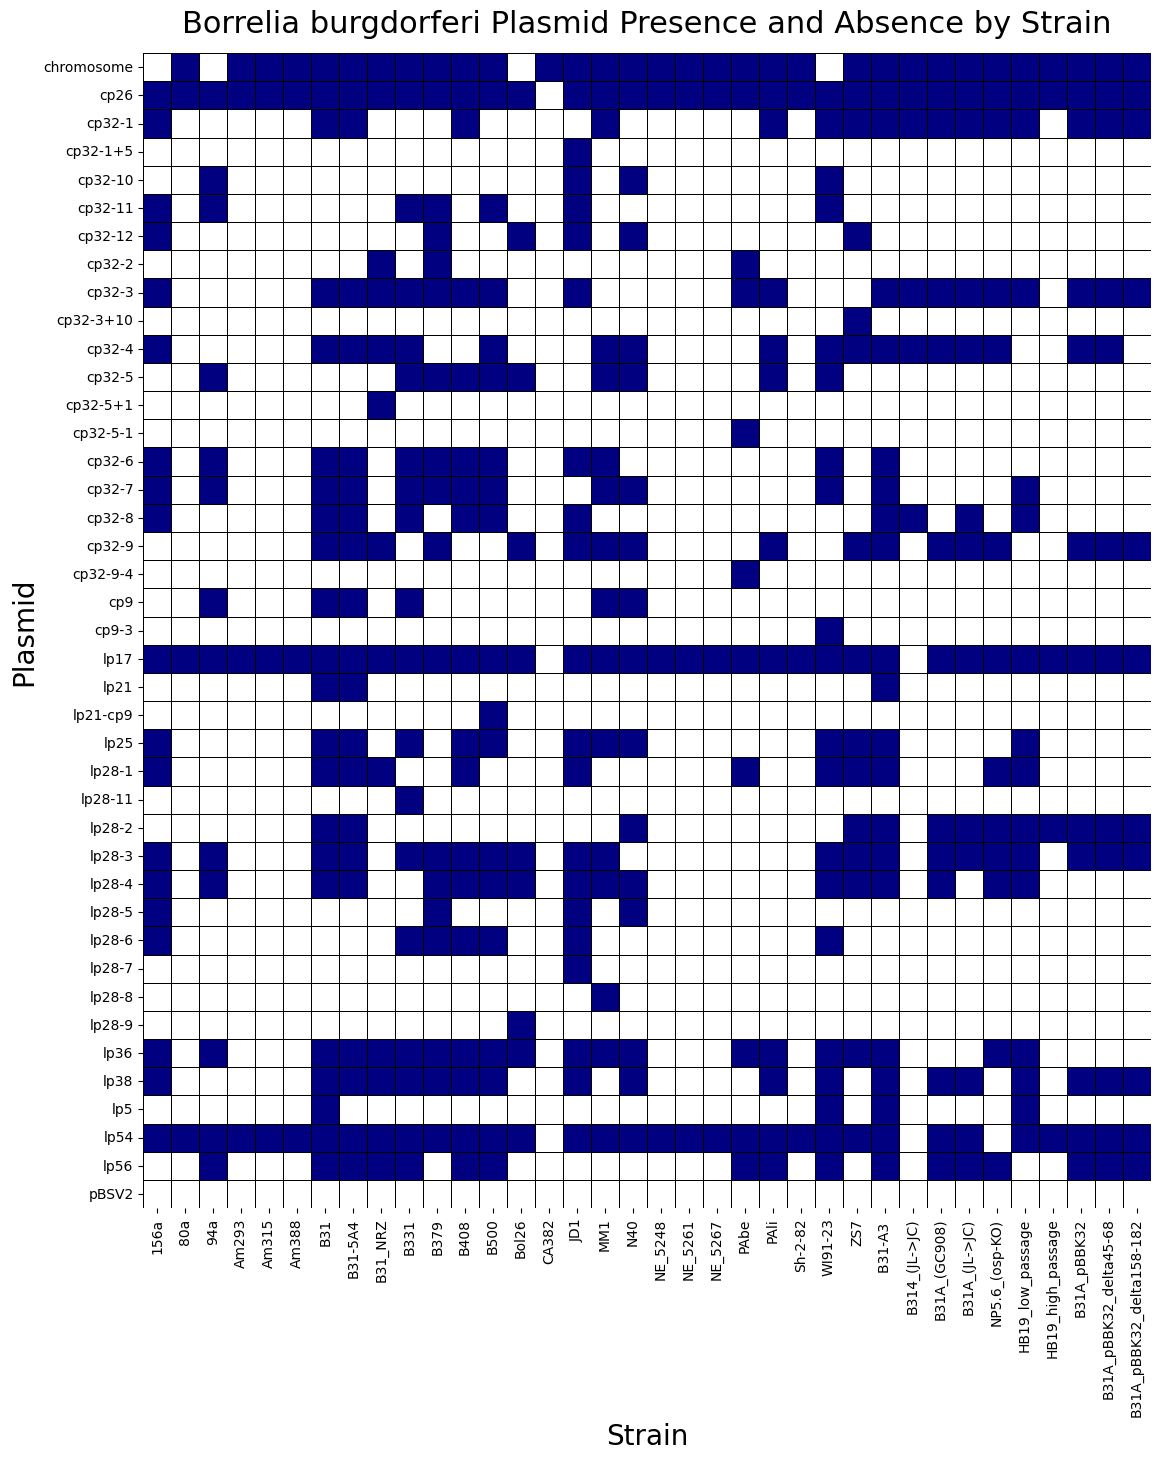

In [22]:
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt

cmap = sns.color_palette("blend:White,Navy",2)
plt.figure(figsize=(13,15))
matrix = sns.heatmap(merged_table, linewidths=0.5, linecolor='black', cmap=cmap, xticklabels=True, yticklabels=True,cbar=False )
#colorbar = matrix.collections[0].colorbar
#colorbar.set_ticks([0, 1])
#colorbar.set_ticklabels(['Absent', 'Present',])
matrix.set_ylabel("Plasmid", size=20)
matrix.set_xlabel("Strain", size=20)
matrix.set_title("Borrelia burgdorferi Plasmid Presence and Absence by Strain", fontsize=22, pad=15)
plt.savefig(output_plots+"/plasmid_heatmap_NCBI.png", dpi=300,bbox_inches='tight', pad_inches=0.5)

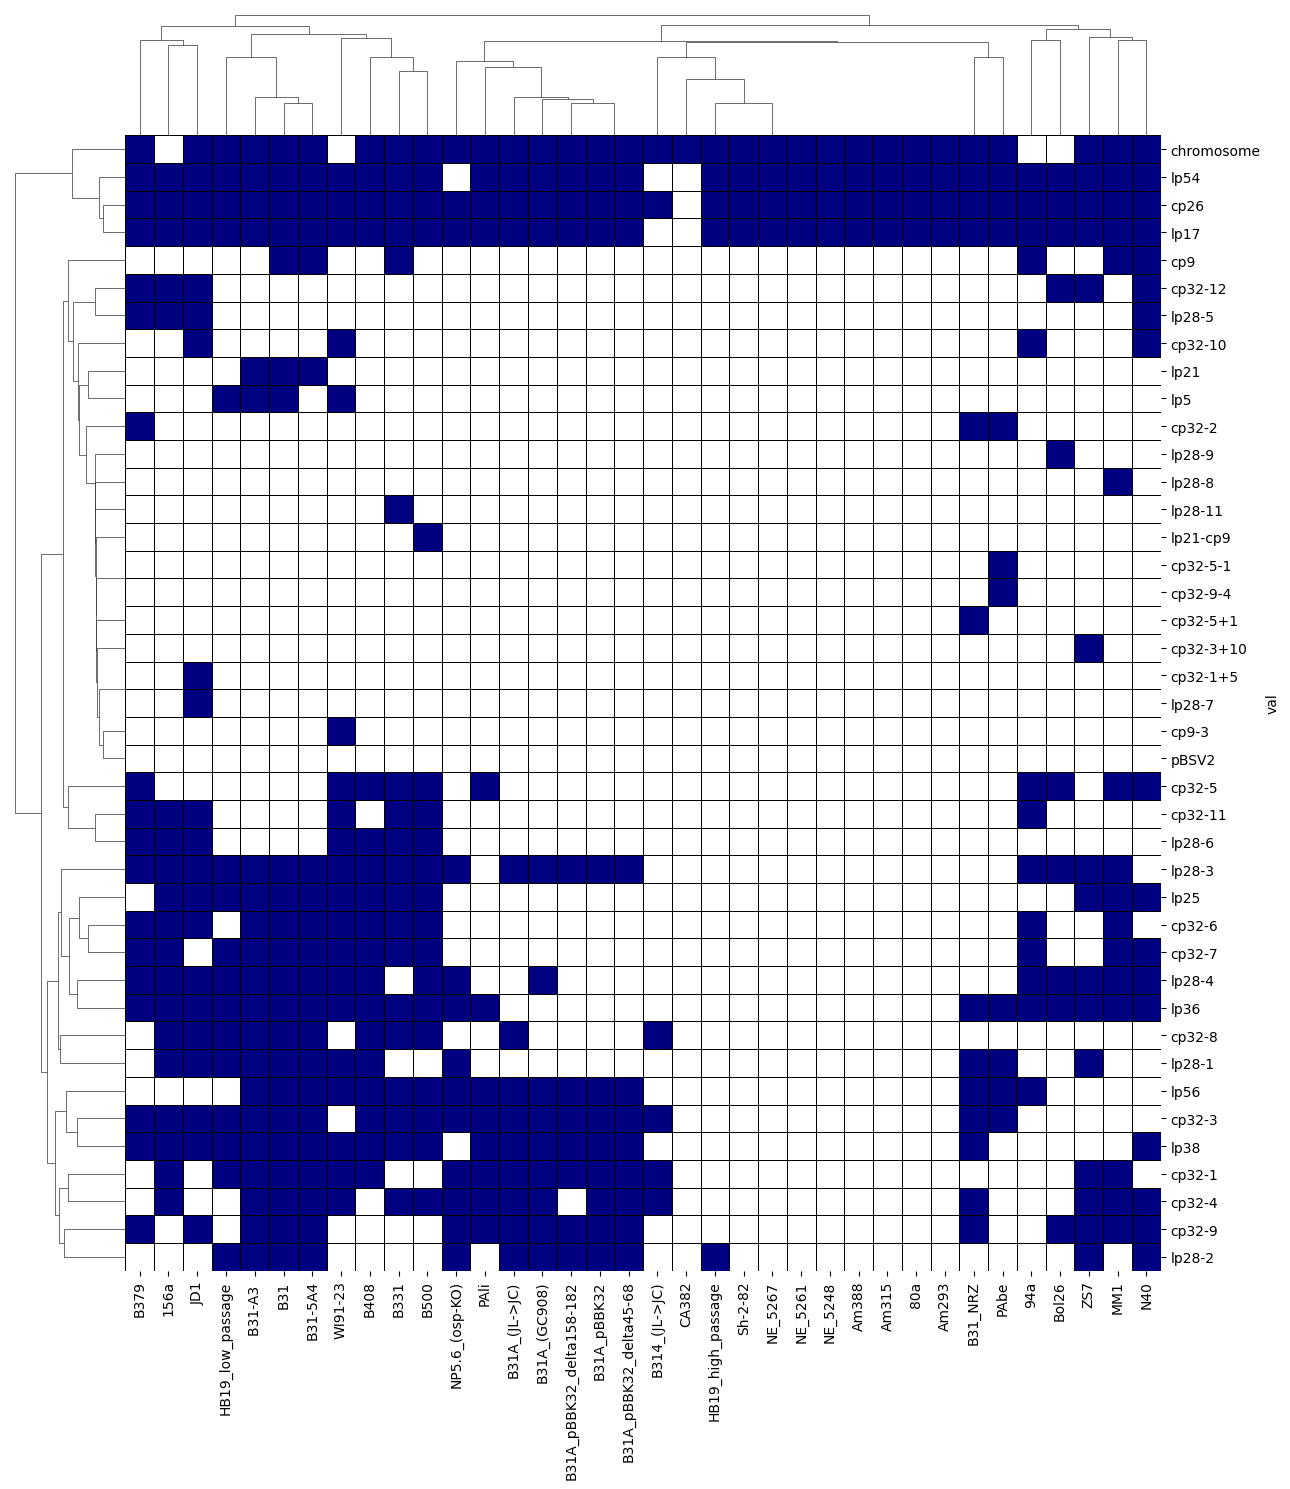

In [23]:
matrix_cluster = sns.clustermap(merged_table, figsize = (13,15), 
                        dendrogram_ratio = 0.1, metric='minkowski', 
                        cmap=cmap, linewidths=0.5, linecolor='black',
                        cbar_pos=None)
#colorbar.set_ticks([0, 1])
#colorbar.set_ticklabels(['Absent', 'Present',])
plt.savefig(output_plots+"/plasmid_heatmap_clustering_NCBI.png", dpi=500, bbox_inches='tight')

# Lets prep the sequences for the blast DB
This also creates the translation dicts to go from NCBI ID to plasmid ID.

In [24]:
import os
import csv
import glob
import json 
import tqdm
import pandas
import pprint
import subprocess
import Bio
import re
from Bio        import SeqIO
from Bio        import SeqRecord
from Bio.Seq    import Seq
from Bio.Blast import NCBIXML
from Bio import SearchIO
from time import sleep
from pathlib import Path

In [25]:
# simple QOL function
def plist(list: list):
    print('\n'.join(list))

In [26]:
WRITE_FASTA_BOOL = False
working_directory = '/Users/mf019/bioinformatics/blastDB/BbPlasmid/plasmid_seqs/fresh_attempt/'
input_fastas = working_directory+'NCBI_sequences/ncbi_dataset/data/'
blast_db_dir = '/Users/mf019/bioinformatics/blastDB/BbPlasmid/db/db_attempt_2'
fasta_db_out = blast_db_dir+'/all_plasmids.fasta'
files_to_use = '/Users/mf019/bioinformatics/blastDB/BbPlasmid/plasmid_seqs/fresh_attempt/output/tsv/acc_to_plasmid.tsv'

In [27]:
os.chdir(path=working_directory)
genomes = glob.glob('**/*.fna', recursive=True)
print("number of fasta files present: ",len(genomes))
#plist(genomes)

good_files = pandas.read_csv(files_to_use, delimiter='\t', header=0)
#plist(good_files['Strain'])

number of fasta files present:  33


In [28]:
gf_dict = good_files.set_index('ID').to_dict('index')
#pprint.pprint(gf_dict)

In [29]:
seq_dict = {}

for file in genomes:
    with open(file) as handle:
        for record in SeqIO.parse(handle, "fasta"):
            if record.id not in seq_dict:
                seq_dict[record.id] = record
                #print(record.id)

#pprint.pprint(seq_dict)

In [30]:
# ok so now lets subset based on being a complete plasmid and not some unassembled shotgun contig

#print(len(seq_dict))
blast_seq_dict = {x:seq_dict[x] for x in good_files['ID']}
#print(len(blast_seq_dict))
#pprint.pprint(blast_seq_dict)

for key in blast_seq_dict:
    curr_plasmid = blast_seq_dict[key]
    curr_plasmid.name = gf_dict[key]['Plasmid']
    if 'length' not in curr_plasmid.annotations:
        curr_plasmid.annotations['length'] = len(curr_plasmid.seq)
    else:
        curr_plasmid.annotations['length'] = len(curr_plasmid.seq)
    if 'strain' not in curr_plasmid.annotations:
        curr_plasmid.annotations['Strain'] = gf_dict[key]['Strain']
    else:
        curr_plasmid.annotations['length'] = len(curr_plasmid.seq)

In [31]:
# lets set up the dictionary for parsing. (I think)

blast_parsing_dict = {}
for plasmid in blast_seq_dict:
    curr_plasmid = blast_seq_dict[plasmid]
    ID = curr_plasmid.id
    name = curr_plasmid.name
    length = len(curr_plasmid.seq)
    strain = curr_plasmid.annotations['Strain']
    #print(ID, name, length, strain)
    if ID not in blast_parsing_dict:
        blast_parsing_dict[ID] = {'ID' : ID, 'name' : name, 'length' : length, 'strain' : strain}
# ok cool the biopython method is much much cleaner. I'm glad I'm getting more familiar with it.


In [60]:

# lets also pickle the blast_parsing_dict to use for matrix gen and strain assignment.
bsd_outfile = open(output_pickles+"blast_parsing_dict.pickle", 'ab')
pickle.dump(blast_parsing_dict, bsd_outfile)
bsd_outfile.close()

In [32]:
# so biopython needs a list of sequences and won't comprehend this dict.
# easy enough
seq_list = []
for key in blast_seq_dict:
    curr_plasmid = blast_seq_dict[key]
    seq_list.append(curr_plasmid)
#print(seq_list)

In [33]:
# ok so now lets write this fasta file containing all of the sequences for the blastDB
if WRITE_FASTA_BOOL == True:
    SeqIO.write(seq_list, fasta_db_out, "fasta")
else:
    print("Not overwriting the fasta file for the DB creation step!")

Not overwriting the fasta file for the DB creation step!


In [34]:
# lets also pickle the blast_seq_dict to use for clustal
bsd_outfile = open(output_pickles+"all_plasmids.pickle", 'ab')
pickle.dump(blast_seq_dict, bsd_outfile)
bsd_outfile.close()

# Blast DB creation
Okay so the following requires setting up a jupyter server in the x86 conda environment

to do this, open a new terminal and type the following:
```$bash
>condax86
>conda activate blast
>cd /Users/mf019/bioinformatics/blastDB/BbPlasmid
>jupyter notebook
```
then grab the server URL and put that into the python kernel option in VSCode
http://localhost:8888/tree?token=b783c19720292ce981bed187f7550a10bfebf745d7e14cb8

click the python3 kernel button in the top right
-> select another kernel -> existing jupyter server 
-> enter URL


In [35]:
RUN_DB_BOOL = False
RUN_BLAST_CANU = False
RUN_BLAST_FLYE = False
RUN_BLAST_PACBIO = False
RUN_BLAST_HYBRID = False
working_directory = '/Users/mf019/bioinformatics/blastDB/BbPlasmid'
fasta_for_db = 'db/db_attempt_2/all_plasmids.fasta'
blast_db = 'db/db_attempt_2/db/plasmid_db'
assembly_dir = 'assemblies/'
BLAST_OUT = 'plasmid_seqs/fresh_attempt/output/blast_results/'
canu_blast_out = BLAST_OUT+'/canu/'
flye_blast_out = BLAST_OUT+'/flye/'
pacbio_blast_out = BLAST_OUT+'/pacbio/'
hybrid_blast_out = BLAST_OUT+'/hybrid_asm/'

try:
    os.makedirs(pacbio_blast_out)
except:
    print("pacbio directory already exists!")
try:
    os.makedirs(hybrid_blast_out)
except:
    print("hybrid blast directory already exists!")


In [36]:

print("CWD: ",os.getcwd())
print("moving to working directory!")
os.chdir(working_directory)
print("CWD: ",os.getcwd())


CWD:  /Users/mf019/bioinformatics/blastDB/BbPlasmid/plasmid_seqs/fresh_attempt
moving to working directory!
CWD:  /Users/mf019/bioinformatics/blastDB/BbPlasmid


In [37]:

# lets glob the assemblies from their respective directories!
canu_assemblies = glob.glob(assembly_dir+'canu/*.fasta')
flye_assemblies = glob.glob(assembly_dir+'flye/*.fasta')

canu_pbar = tqdm.tqdm(range(len(canu_assemblies)), desc="Canu Assemblies Found: ")
for file in canu_assemblies:
    sleep(0.1)
    canu_pbar.update(1)
canu_pbar.close()
    
flye_pbar = tqdm.tqdm(range(len(flye_assemblies)), desc="Flye assemblies found: ")
for file in flye_assemblies:
    sleep(0.1)
    flye_pbar.update(1)
flye_pbar.close()


Canu Assemblies Found: : 0it [00:00, ?it/s]
Flye assemblies found: : 0it [00:00, ?it/s]


In [38]:

if RUN_DB_BOOL is True:
    make_db_cmd = "makeblastdb -in "+fasta_for_db+" -out "+blast_db+" -dbtype 'nucl' -hash_index"
    print(make_db_cmd)
    subprocess.run(make_db_cmd, shell=True)

else:
    print("Blast DB already exists! Not creating it again!")
    print("Change RUN_DB_BOOL to True if you need to rebuild the DB.")


Blast DB already exists! Not creating it again!
Change RUN_DB_BOOL to True if you need to rebuild the DB.


# Now let's blast our contigs! 

In [39]:
if RUN_BLAST_CANU == True:
    # Run Blast on all Canu Assemblies!
    num_files = len(canu_assemblies)
    canu_pbar = tqdm.tqdm(total=num_files, desc="Canu Assemblies Blasted: ")
    for input_file in canu_assemblies:
        path = Path(input_file)
        suffix = path.suffixes[0]
        assembly_id = path.name.split(suffix)[0]
        output_file = canu_blast_out+assembly_id+"_canu_blast"
        blast_cmd = "blastn -query "+input_file+" -task 'blastn' "
        blast_cmd += "-db "+blast_db
        blast_cmd += " -out "+output_file+".xml"
        blast_cmd += " -evalue 1e-100 -num_threads 8 -outfmt 5 -max_target_seqs 5 -max_hsps 1"
        subprocess.run(blast_cmd, shell=True)
        canu_pbar.update(1)
    canu_pbar.close()
else:
    print("not re-running blast on canu assemblies!")

if RUN_BLAST_FLYE == True:
    # run Blast on all flye assemblies
    num_files = len(flye_assemblies)
    flye_pbar = tqdm.tqdm(total=num_files, desc="Flye Assemblies Blasted: ")
    for input_file in flye_assemblies:
        path = Path(input_file)
        suffix = path.suffixes[0]
        assembly_id = path.name.split(suffix)[0]
        output_file = flye_blast_out+assembly_id+"_flye_blast"
        blast_cmd = "blastn -query "+input_file+" -task 'blastn' "
        blast_cmd += "-db "+blast_db
        blast_cmd += " -out "+output_file+".xml"
        blast_cmd += " -evalue 1e-100 -num_threads 8 -outfmt 5 -max_target_seqs 5 -max_hsps 1"
        subprocess.run(blast_cmd, shell=True)
        flye_pbar.update(1)
    flye_pbar.close()
else:
    print("Not re-running blast on flye assemblies")

not re-running blast on canu assemblies!
Not re-running blast on flye assemblies


In [40]:
pacbio_assemblies = glob.glob('assemblies/pacbio/*.fa*', recursive=True)
print("number of pacbio assemblies present: ",len(pacbio_assemblies))
hybrid_assemblies = glob.glob('assemblies/hybrid_asm/*.fa*', recursive=True)
print("number of hybrid assemblies present: ",len(hybrid_assemblies))

if RUN_BLAST_PACBIO == True:
    # Run Blast on all pacbio Assemblies!
    num_files = len(pacbio_assemblies)
    pacbio_pbar = tqdm.tqdm(total=num_files, desc="Pacbio Assemblies Blasted: ")
    for input_file in pacbio_assemblies:
        path = Path(input_file)
        suffix = path.suffixes[0]
        assembly_id = path.name.split(suffix)[0]
        output_file =pacbio_blast_out+assembly_id+"_pacbio_blast"
        blast_cmd = "blastn -query "+input_file+" -task 'blastn' "
        blast_cmd += "-db "+blast_db
        blast_cmd += " -out "+output_file+".xml"
        blast_cmd += " -evalue 1e-100 -num_threads 8 -outfmt 5 -max_target_seqs 5 -max_hsps 1"
        subprocess.run(blast_cmd, shell=True)
        pacbio_pbar.update(1)
    pacbio_pbar.close()
else:
    print("not re-running blast on pacbio assemblies!")
    
if RUN_BLAST_HYBRID == True:
    # Run Blast on all hybrid Assemblies!
    num_files = len(hybrid_assemblies)
    hybrid_pbar = tqdm.tqdm(total=num_files, desc="Hybrid Assemblies Blasted: ")
    for input_file in hybrid_assemblies:
        path = Path(input_file)
        suffix = path.suffixes[0]
        assembly_id = path.name.split(suffix)[0]
        output_file = hybrid_blast_out+assembly_id+"_hybrid_blast"
        blast_cmd = "blastn -query "+input_file+" -task 'blastn' "
        blast_cmd += "-db "+blast_db
        blast_cmd += " -out "+output_file+".xml"
        blast_cmd += " -evalue 1e-100 -num_threads 8 -outfmt 5 -max_target_seqs 5 -max_hsps 1"
        subprocess.run(blast_cmd, shell=True)
        hybrid_pbar.update(1)
    hybrid_pbar.close()
else:
    print("not re-running blast on hybrid assemblies!")

number of pacbio assemblies present:  20
number of hybrid assemblies present:  47
not re-running blast on pacbio assemblies!
not re-running blast on hybrid assemblies!


# Need to Input Assembly Data
I need to know the length of each contig. Might as well parse in the entire assembly since I've already got a method ready to plug n chug

In [41]:
os.chdir(path=working_directory)
canu_assemblies = glob.glob('assemblies/canu/*.fa*', recursive=True)
print("number of canu assemblies present: ",len(canu_assemblies))

flye_assemblies = glob.glob('assemblies/flye/*.fa*', recursive=True)
print("number of flye assemblies present: ",len(flye_assemblies))


number of canu assemblies present:  0
number of flye assemblies present:  0


In [42]:
pacbio_assemblies = glob.glob('assemblies/pacbio/*.fa*', recursive=True)
print("number of pacbio assemblies present: ",len(pacbio_assemblies))

hybrid_assemblies = glob.glob('assemblies/hybrid_asm/*.fa*', recursive=True)
print("number of hybrid assemblies present: ",len(hybrid_assemblies))

number of pacbio assemblies present:  20
number of hybrid assemblies present:  47


In [43]:
assembly_seq_dict = {'canu' : {}, 'flye' : {}, 'pacbio' : {}, 'hybrid' : {}}

for file in canu_assemblies:
    canu_dict = assembly_seq_dict['canu']
    path = Path(file)
    suffix = path.suffixes[0]
    barcode = path.name.split(suffix)[0].replace("_canu_blast", "") 
    if barcode not in canu_dict:
        canu_dict[barcode] = {}

    barcode_dict = canu_dict[barcode]
    
    with open(file) as handle:
        for record in SeqIO.parse(handle, "fasta"):
            if record.id not in barcode_dict:
                barcode_dict[record.id] = record
                print(file, record.id)

for file in flye_assemblies:
    flye_dict = assembly_seq_dict['flye']
    path = Path(file)
    suffix = path.suffixes[0]
    barcode = path.name.split(suffix)[0].replace("_flye_blast", "")

    if barcode not in flye_dict:
        flye_dict[barcode] = {}

    barcode_dict = flye_dict[barcode]
    
    with open(file) as handle:
        for record in SeqIO.parse(handle, "fasta"):
            if record.id not in barcode_dict:
                barcode_dict[record.id] = record
                print(file, record.id)


In [44]:

for file in pacbio_assemblies:
    pacbio_dict = assembly_seq_dict['pacbio']
    path = Path(file)
    suffix = path.suffixes[0]
    barcode = path.name.split(suffix)[0]+"_pacbio"
    print(barcode)
    if barcode not in pacbio_dict:
        pacbio_dict[barcode] = {}

    barcode_dict = pacbio_dict[barcode]
    
    with open(file) as handle:
        for record in SeqIO.parse(handle, "fasta"):
            if record.id not in barcode_dict:
                barcode_dict[record.id] = record
                #print(file, record.id)
                
for file in hybrid_assemblies:
    hybrid_assemblies_dict = assembly_seq_dict['hybrid']
    path = Path(file)
    suffix = path.suffixes[0]
    barcode = path.name.split(suffix)[0]+"_hybrid"
    print(barcode)
    
    if barcode not in hybrid_assemblies_dict:
        hybrid_assemblies_dict[barcode] = {}

    barcode_dict = hybrid_assemblies_dict[barcode]
    
    with open(file) as handle:
        for record in SeqIO.parse(handle, "fasta"):
            if record.id not in barcode_dict:
                barcode_dict[record.id] = record
                #print(file, record.id)

B500_pacbio
MC104_pacbio
B483_pacbio
MC105_pacbio
BL206_pacbio
BL522_pacbio
B331_pacbio
MR616_pacbio
BL546_pacbio
MC149_pacbio
B247_pacbio
B356_pacbio
B418_pacbio
MR614_pacbio
BL515_pacbio
MR641_pacbio
B477_pacbio
BL224_pacbio
B348_pacbio
MC123_pacbio
K7_hybrid
K60_hybrid
K25_hybrid
K71_hybrid
K11_hybrid
K22_hybrid
K19_hybrid
K76_hybrid
K16_hybrid
K82_hybrid
K10_hybrid
K84_hybrid
K70_hybrid


K24_hybrid
K6_hybrid
K17_hybrid
K83_hybrid
K69_hybrid
EU14_B89613_hybrid
L113_hybrid
K18_hybrid
K1_hybrid
K66_hybrid
K80_hybrid
K74_hybrid
K2_hybrid
K13_hybrid
K56_hybrid
K73_hybrid
K59_hybrid
EU57_B190413_hybrid
K62_hybrid
K3_hybrid
K64_hybrid
K21_hybrid
K90_hybrid
XD1_hybrid
EU51_B192411_hybrid
K30_hybrid
K75_hybrid
K15_hybrid
K89_hybrid
K58_hybrid
K72_hybrid
K86_hybrid
K12_hybrid
K57_hybrid


In [45]:
pprint.pprint(assembly_seq_dict.keys())

dict_keys(['canu', 'flye', 'pacbio', 'hybrid'])


# Now lets parse the blast results

In [46]:
working_directory = '/Users/mf019/bioinformatics/blastDB/BbPlasmid'
canu_blast_out = 'plasmid_seqs/fresh_attempt/output/blast_results/canu/'
flye_blast_out = 'plasmid_seqs/fresh_attempt/output/blast_results/flye/'
# pacbio_blast_out # already set above.
# hybrid blast out # already set above"
output_json = 'plasmid_seqs/fresh_attempt/output/json/'
print("moving to working directory!")
os.chdir(working_directory)
print("CWD: ",os.getcwd())

moving to working directory!
CWD:  /Users/mf019/bioinformatics/blastDB/BbPlasmid


In [47]:
canu_blast_results = glob.glob(canu_blast_out+'*.xml')
flye_blast_results = glob.glob(flye_blast_out+'*.xml')

canu_pbar = tqdm.tqdm(range(len(canu_blast_results)), desc="Canu blast results found: ")
for file in canu_blast_results:
    sleep(0.01)
    canu_pbar.update(1)
canu_pbar.close()
    
flye_pbar = tqdm.tqdm(range(len(flye_blast_results)), desc="Flye blast results found: ")
for file in flye_blast_results:
    sleep(0.01)
    flye_pbar.update(1)
flye_pbar.close()

Flye blast results found: 100%|██████████| 4/4 [00:00<00:00, 89.39it/s]


In [48]:
pacbio_blast_results = glob.glob(pacbio_blast_out+'*.xml')
hybrid_blast_results = glob.glob(hybrid_blast_out+'*.xml')

pacbio_pbar = tqdm.tqdm(range(len(pacbio_blast_results)), desc="pacbio blast results found: ")
for file in pacbio_blast_results:
    sleep(0.01)
    pacbio_pbar.update(1)
pacbio_pbar.close()

hybrid_pbar = tqdm.tqdm(range(len(hybrid_blast_results)), desc="hybrid blast results found: ")
for file in hybrid_blast_results:
    sleep(0.01)
    hybrid_pbar.update(1)
hybrid_pbar.close()

hybrid blast results found: 100%|██████████| 47/47 [00:00<00:00, 86.35it/s]


In [49]:
#for file in canu_blast_results:
#    blast_qresult = SearchIO.parse(file, "blast-xml")
#    for record in blast_qresult:
#        print(record)

In [50]:
all_hits_dict = {}

In [51]:
all_hits_dict['canu'] = {}
canu_hits_dict = all_hits_dict['canu']

for file in canu_blast_results:

    path = Path(file)
    suffix = path.suffixes[0]
    assembly_id = path.name.split(suffix)[0].replace("_canu_blast", "")

    if assembly_id not in canu_hits_dict:
        canu_hits_dict[assembly_id] = {}
        
    current_barcode = canu_hits_dict[assembly_id]

    res_handle = open(file)
    blast_records = NCBIXML.parse(res_handle)

    for record in blast_records:
        for alignment in record.alignments:
            for hsp in alignment.hsps:
                if (hsp.expect == 0 or hsp.expect < 1*10^-100):
                    query_length = record.query_length
                    contig_id = record.query.split(" ")[0]
                    hit_id = alignment.title.split(" ")[1]
                    alignment_length = alignment.length
                    bit_score = hsp.score
                    evalue = hsp.expect
                    if contig_id not in current_barcode:
                        current_barcode[contig_id] = [{'ID' : hit_id, 'alignment_length' : alignment_length, 'query_length' : query_length, 'bit_score' : bit_score, 'e-value' : evalue}]
                    else:
                        current_barcode[contig_id].append({'ID' : hit_id, 'alignment_length' : alignment_length, 'query_length' : query_length, 'bit_score' : bit_score, 'e-value' : evalue})
                    #print("****Alignment****")
                    #print("Barcode: ", assembly_id)
                    #print("contig ID: ", contig_id)
                    #print("sequence:", hit_id)
                    #print("length:", alignment.length)
                    #print("bit score:",hsp.score)
                    #print("e value:", hsp.expect)

pprint.pprint(all_hits_dict['canu'])
#out_file = open(output_json+'canu_hits.json', "w")
#json.dump(all_hits_dict['canu'],out_file, indent=6)

{'barcode01': {'tig00000001': [{'ID': 'CP019767.1',
                                'alignment_length': 909921,
                                'bit_score': 959925.0,
                                'e-value': 0.0,
                                'query_length': 906468},
                               {'ID': 'CP019844.1',
                                'alignment_length': 909921,
                                'bit_score': 959889.0,
                                'e-value': 0.0,
                                'query_length': 906468},
                               {'ID': 'CP002228.1',
                                'alignment_length': 902191,
                                'bit_score': 905531.0,
                                'e-value': 0.0,
                                'query_length': 906468},
                               {'ID': 'CP019916.1',
                                'alignment_length': 910728,
                                'bit_score': 849134.0,
                 

In [52]:
all_hits_dict['flye'] = {}
flye_hits_dict = all_hits_dict['flye']

for file in flye_blast_results:

    path = Path(file)
    suffix = path.suffixes[0]
    assembly_id = path.name.split(suffix)[0].replace("_flye_blast", "")

    if assembly_id not in flye_hits_dict:
        flye_hits_dict[assembly_id] = {}
        
    current_barcode = flye_hits_dict[assembly_id]

    res_handle = open(file)
    blast_records = NCBIXML.parse(res_handle)

    for record in blast_records:
        for alignment in record.alignments:
            for hsp in alignment.hsps:
                if (hsp.expect == 0 or hsp.expect < 1*10^-100):
                    contig_id = record.query.split(" ")[0]
                    hit_id = alignment.title.split(" ")[1]
                    alignment_length = alignment.length
                    query_length = record.query_length
                    print(query_length)
                    bit_score = hsp.score
                    evalue = hsp.expect
                    if contig_id not in current_barcode:
                        current_barcode[contig_id] = [{'ID' : hit_id, 'alignment_length' : alignment_length, 'query_length' : query_length, 'bit_score' : bit_score, 'e-value' : evalue}]
                    else:
                        current_barcode[contig_id].append({'ID' : hit_id, 'alignment_length' : alignment_length, 'query_length' : query_length, 'bit_score' : bit_score, 'e-value' : evalue})
                    #print("****Alignment****")
                    print("Barcode: ", assembly_id)
                    print("contig ID: ", contig_id)
                    #print("sequence:", hit_id)
                    #print("length:", alignment.length)
                    #print("bit score:",hsp.score)
                    #print("e value:", hsp.expect)

pprint.pprint(all_hits_dict['flye'])
#out_file = open(output_json+'flye_hits.json', "w")
#json.dump(all_hits_dict['flye'],out_file, indent=6)

957015
Barcode:  barcode01
contig ID:  contig_1
957015
Barcode:  barcode01
contig ID:  contig_1
957015
Barcode:  barcode01
contig ID:  contig_1
957015
Barcode:  barcode01
contig ID:  contig_1
957015
Barcode:  barcode01
contig ID:  contig_1
93485
Barcode:  barcode01
contig ID:  contig_2
93485
Barcode:  barcode01
contig ID:  contig_2
93485
Barcode:  barcode01
contig ID:  contig_2
93485
Barcode:  barcode01
contig ID:  contig_2
93485
Barcode:  barcode01
contig ID:  contig_2
1791
Barcode:  barcode01
contig ID:  contig_3
1791
Barcode:  barcode01
contig ID:  contig_3
1791
Barcode:  barcode01
contig ID:  contig_3
1791
Barcode:  barcode01
contig ID:  contig_3
1791
Barcode:  barcode01
contig ID:  contig_3
1628
Barcode:  barcode01
contig ID:  contig_4
1628
Barcode:  barcode01
contig ID:  contig_4
1628
Barcode:  barcode01
contig ID:  contig_4
1628
Barcode:  barcode01
contig ID:  contig_4
1628
Barcode:  barcode01
contig ID:  contig_4
33635
Barcode:  barcode01
contig ID:  contig_5
33635
Barcode:  ba

In [53]:
all_hits_dict['pacbio'] = {}
pacbio_hits_dict = all_hits_dict['pacbio']

for file in pacbio_blast_results:

    path = Path(file)
    suffix = path.suffixes[0]
    assembly_id = path.name.split(suffix)[0].replace("_blast", "")

    if assembly_id not in pacbio_hits_dict:
        pacbio_hits_dict[assembly_id] = {}
        
    current_barcode = pacbio_hits_dict[assembly_id]

    res_handle = open(file)
    blast_records = NCBIXML.parse(res_handle)

    for record in blast_records:
        for alignment in record.alignments:
            for hsp in alignment.hsps:
                if (hsp.expect == 0 or hsp.expect < 1*10^-100):
                    query_length = record.query_length
                    contig_id = record.query.split(" ")[0]
                    hit_id = alignment.title.split(" ")[1]
                    alignment_length = alignment.length
                    bit_score = hsp.score
                    evalue = hsp.expect
                    if contig_id not in current_barcode:
                        current_barcode[contig_id] = [{'ID' : hit_id, 'alignment_length' : alignment_length, 'query_length' : query_length, 'bit_score' : bit_score, 'e-value' : evalue}]
                    else:
                        current_barcode[contig_id].append({'ID' : hit_id, 'alignment_length' : alignment_length, 'query_length' : query_length, 'bit_score' : bit_score, 'e-value' : evalue})
                    #print("****Alignment****")
                    #print("Barcode: ", assembly_id)
                    #print("contig ID: ", contig_id)
                    #print("sequence:", hit_id)
                    #print("length:", alignment.length)
                    #print("bit score:",hsp.score)
                    #print("e value:", hsp.expect)

pprint.pprint(all_hits_dict['pacbio'])
out_file = open(output_json+'pacbio_hits.json', "w")
json.dump(all_hits_dict['pacbio'],out_file, indent=6)

{'B247_pacbio': {'B247_chr': [{'ID': 'CP094579.1',
                               'alignment_length': 920773,
                               'bit_score': 1821360.0,
                               'e-value': 0.0,
                               'query_length': 915733},
                              {'ID': 'CP124080.1',
                               'alignment_length': 907764,
                               'bit_score': 1814812.0,
                               'e-value': 0.0,
                               'query_length': 915733},
                              {'ID': 'CP002312.1',
                               'alignment_length': 922801,
                               'bit_score': 1788192.0,
                               'e-value': 0.0,
                               'query_length': 915733},
                              {'ID': 'CP124084.1',
                               'alignment_length': 910563,
                               'bit_score': 1746760.0,
                               

In [54]:
all_hits_dict['hybrid'] = {}
hybrid_hits_dict = all_hits_dict['hybrid']

for file in hybrid_blast_results:

    path = Path(file)
    suffix = path.suffixes[0]
    assembly_id = path.name.split(suffix)[0].replace("_blast", "")

    if assembly_id not in hybrid_hits_dict:
        hybrid_hits_dict[assembly_id] = {}
        
    current_barcode = hybrid_hits_dict[assembly_id]

    res_handle = open(file)
    blast_records = NCBIXML.parse(res_handle)

    for record in blast_records:
        for alignment in record.alignments:
            for hsp in alignment.hsps:
                if (hsp.expect == 0 or hsp.expect < 1*10^-100):
                    query_length = record.query_length
                    contig_id = record.query.split(" ")[0]
                    hit_id = alignment.title.split(" ")[1]
                    alignment_length = alignment.length
                    bit_score = hsp.score
                    evalue = hsp.expect
                    if contig_id not in current_barcode:
                        current_barcode[contig_id] = [{'ID' : hit_id, 'alignment_length' : alignment_length, 'query_length' : query_length, 'bit_score' : bit_score, 'e-value' : evalue}]
                    else:
                        current_barcode[contig_id].append({'ID' : hit_id, 'alignment_length' : alignment_length, 'query_length' : query_length, 'bit_score' : bit_score, 'e-value' : evalue})
                    #print("****Alignment****")
                    #print("Barcode: ", assembly_id)
                    #print("contig ID: ", contig_id)
                    #print("sequence:", hit_id)
                    #print("length:", alignment.length)
                    #print("bit score:",hsp.score)
                    #print("e value:", hsp.expect)

pprint.pprint(all_hits_dict['hybrid'])
out_file = open(output_json+'hybrid_hits.json', "w")
json.dump(all_hits_dict['hybrid'],out_file, indent=6)

{'EU14_B89613_hybrid': {'contig000001': [{'ID': 'CP124096.1',
                                          'alignment_length': 910422,
                                          'bit_score': 1390021.0,
                                          'e-value': 0.0,
                                          'query_length': 910442},
                                         {'ID': 'CP124100.1',
                                          'alignment_length': 910422,
                                          'bit_score': 1390012.0,
                                          'e-value': 0.0,
                                          'query_length': 910442},
                                         {'ID': 'CP124088.1',
                                          'alignment_length': 910229,
                                          'bit_score': 1381519.0,
                                          'e-value': 0.0,
                                          'query_length': 910442},
                               

# this section was more of a visual check to see how the data looked. Doesn't need to run to complete analysis.

In [55]:
#canu_hits_dict = all_hits_dict['canu']
#
##pprint.pprint(blast_parsing_dict)
#for file in canu_hits_dict:
#    assembly_id = file
#    barcode = canu_hits_dict[file]
#    for contig in barcode:
#        query = barcode[contig]
#        assembly_contig = assembly_seq_dict['canu'][assembly_id][contig]
#        for item in enumerate(query):
#            hit = item[1]
#            
#            hit_ID = hit['ID']
#            hit_bscore = hit['bit_score']
#            hit_evalue = hit['e-value']
#            hit_querylen = hit['query_length']
#            hit_alnlen = hit['alignment_length']
#            
#            ref_plasmid_name = blast_parsing_dict[hit_ID]['name']
#            ref_plasmid_length = blast_parsing_dict[hit_ID]['length']
#            ref_plasmid_strain = blast_parsing_dict[hit_ID]['strain']
#            
#            c_offset = ' '*len(contig)
#            i_offset = ' '*len(hit_ID)
#            if len(ref_plasmid_name) < len(hit_ID):
#                n_offset = ' '*(len(hit_ID)-len(ref_plasmid_name)-1)
#            else:
#                n_offset = ' '*0
#            print(" barcode: ", assembly_id)
#            print("assembly: ", assembly_contig.name,i_offset,len(assembly_contig.seq))
#            print("   BLAST: ", contig, hit_ID, hit_querylen, hit_alnlen, hit_bscore)
#            print("    NCBI: ", i_offset, ref_plasmid_name, n_offset,ref_plasmid_length,ref_plasmid_strain)
#            #print('\n')
#            #print(blast_parsing_dict[hit_ID])
#
### I need to finish this up and actually get it into the translated_barcode_dict so I can re-run the above matrix functions on it and generate a heatmap but my brain is currently the consistency of Jello.

# Again, another check

In [58]:
for key in assembly_seq_dict:
    print(key)
    for key2 in assembly_seq_dict[key]:
        print(key2)
        print(assembly_seq_dict[key][key2].keys())

canu
flye
pacbio
B500_pacbio
dict_keys(['B500_chr', 'B500_cp26', 'B500_cp32-10', 'B500_cp32-11', 'B500_cp32-1', 'B500_cp32-4', 'B500_cp32-5', 'B500_cp32-6', 'B500_cp32-7', 'B500_lp17', 'B500_lp21+cp9', 'B500_lp25', 'B500_lp28-3', 'B500_lp28-4', 'B500_lp28-6', 'B500_lp36', 'B500_lp38', 'B500_lp54', 'B500_lp56'])
MC104_pacbio
dict_keys(['MC104_chr', 'MC104_cp26', 'MC104_cp32-1', 'MC104_cp32-11', 'MC104_cp32-3', 'MC104_cp32-4', 'MC104_cp32-6', 'MC104_cp32-7', 'MC104_lp17', 'MC104_lp25', 'MC104_lp28-1', 'MC104_lp28-3', 'MC104_lp28-4', 'MC104_lp28-5', 'MC104_lp36', 'MC104_lp38', 'MC104_lp54'])
B483_pacbio
dict_keys(['B483_chr', 'B483_cp26', 'B483_cp32-1', 'B483_cp32-3', 'B483_cp32-4', 'B483_cp32-8', 'B483_cp9', 'B483_lp17', 'B483_lp25', 'B483_lp28-3', 'B483_lp28-4', 'B483_lp28-5', 'B483_lp28-7', 'B483_lp28-8', 'B483_lp36', 'B483_lp38', 'B483_lp54'])
MC105_pacbio
dict_keys(['MC105_chr', 'MC105_cp26', 'MC105_cp32-1', 'MC105_cp32-11', 'MC105_cp32-12', 'MC105_cp32-3', 'MC105_cp32-4', 'MC105_cp3

In [59]:
translated_barcode_dict = {'canu' : {}, 'flye' : {}, 'pacbio' : {}, 'hybrid' : {}}

for method in all_hits_dict:
    print(method)

    tc_method = translated_barcode_dict[method]

    current_method = all_hits_dict[method]

    for barcode in current_method:
        tc_method[barcode] = {}
        tc_barcode = tc_method[barcode]
        print("\n"+barcode)

        current_barcode = current_method[barcode]
        
        for contig in current_barcode:
            print(contig)

            tc_barcode[contig] = {}
            tc_barcode[contig] = { 'assembly' : assembly_seq_dict[method][barcode][contig], 
                                      'hits' : current_barcode[contig], 
                                  'RefStats' : [] }
            
            tc_contig = tc_barcode[contig]
            #print("\n"+"    "+contig)
            current_contig = current_barcode[contig]
            #print(tc_contig)

            for hit in enumerate(tc_contig['hits']):
                #print(hit[0])
                #print("        "+"hit:",hit[1]['ID'],"lookup table:", blast_parsing_dict[hit[1]['ID']]['name'])
                hit[1]['name'] = blast_parsing_dict[hit[1]['ID']]['name']
                #print("            "+"new name:",hit[1]['ID'], hit[1]['name'])                
                tc_contig['RefStats'].append(blast_parsing_dict[hit[1]['ID']])

canu

barcode01
tig00000001


KeyError: 'barcode01'

In [ ]:
pprint.pprint(translated_barcode_dict)

NameError: name 'pprint' is not defined

In [ ]:
# Need to actually populate the below dictionary before I dump it. 
#pprint.pprint(translated_barcode_dict)
#out_file = open(output_json+'all_hits_pb-hyb.json', "w")
#json.dump(translated_barcode_dict,out_file, indent=6)

In [ ]:
# ok so now we need to generate a plasmid_dict style object for the barcodes we have
sample_plasmid_dict = {}

for method in translated_barcode_dict:
    print("\n"+method)
    current_method = translated_barcode_dict[method]
    for barcode in current_method:
        if barcode not in sample_plasmid_dict:
            sample_plasmid_dict[barcode] = {}
        else:
            pass

        if method not in sample_plasmid_dict[barcode]:
            sample_plasmid_dict[barcode][method] = {}
        else:
                pass
        print("\n"+barcode)
        current_barcode = current_method[barcode]
        sample_plasmid_dict[barcode][method] = []

        cs_barcode = sample_plasmid_dict[barcode][method]
        
        for contig in current_barcode:
            print(method, barcode, contig)
            current_contig = current_barcode[contig]

            assembly = current_contig['assembly']
            assembly_id = assembly.id
            contig_len = len(assembly.seq)
            # need to figure out how to iterate over each hit and pick the longest query 
            # and highest score. ..... tbd
            top_hit = current_contig['hits'][0]
            aln_len = top_hit['alignment_length']
            query_length = top_hit['query_length']
            top_ref = current_contig['RefStats'][0]
            ref_len = top_ref['length']
            #print(assembly_id, contig_len)
            #print(top_hit)
            #print(top_ref)
            aln_diff = ref_len - aln_len
            contig_len_diff = contig_len - aln_len
            #print("                                    contig: ", contig)
            #print("                          length of contig: ", contig_len)
            #print("                       length of alignment: ", aln_len)
            #print("                             length of ref: ", ref_len)
            #print("difference between reference and alignment:", aln_diff)
            #print("   difference between contig and alignment: ", contig_len_diff,"\n")

            cs_barcode.append({'contig_id' : contig, "contig_len" : contig_len, "hit_name" : top_hit['name'], "query_len" : query_length})
            #for hit in current_contig['hits']:
                #print(hit)


canu

barcode01
canu barcode01 tig00000001
canu barcode01 tig00000002
canu barcode01 tig00000006
canu barcode01 tig00000007
canu barcode01 tig00000008
canu barcode01 tig00000009
canu barcode01 tig00000010
canu barcode01 tig00000014
canu barcode01 tig00000015
canu barcode01 tig00000016
canu barcode01 tig00000017
canu barcode01 tig00000018
canu barcode01 tig00000019

barcode04
canu barcode04 tig00000001
canu barcode04 tig00000002
canu barcode04 tig00000005
canu barcode04 tig00000006
canu barcode04 tig00000007
canu barcode04 tig00000008
canu barcode04 tig00000009
canu barcode04 tig00000010

barcode03
canu barcode03 tig00000001
canu barcode03 tig00000002
canu barcode03 tig00000003
canu barcode03 tig00000004
canu barcode03 tig00000005
canu barcode03 tig00000007
canu barcode03 tig00000008
canu barcode03 tig00000009
canu barcode03 tig00000010

barcode02
canu barcode02 tig00000001
canu barcode02 tig00000007
canu barcode02 tig00000008
canu barcode02 tig00000009
canu barcode02 tig00000010
canu 

In [ ]:
pprint.pprint(sample_plasmid_dict)

{'B247_pacbio': {'pacbio': [{'contig_id': 'B247_chr',
                             'contig_len': 915733,
                             'hit_name': 'chromosome',
                             'query_len': 915733},
                            {'contig_id': 'B247_cp26',
                             'contig_len': 26514,
                             'hit_name': 'cp26',
                             'query_len': 26514},
                            {'contig_id': 'B247_cp32-11',
                             'contig_len': 30286,
                             'hit_name': 'cp32-11',
                             'query_len': 30286},
                            {'contig_id': 'B247_cp32-3',
                             'contig_len': 30262,
                             'hit_name': 'cp32-3',
                             'query_len': 30262},
                            {'contig_id': 'B247_cp32-4',
                             'contig_len': 30301,
                             'hit_name': 'cp32-2',
         

# Let's Make a Matrix!

In [ ]:
# ok so idk how to deal with these blast results, need to talk to jake for sure.

# anyway lets just make a matrix to see if we can go from this to that. the actual accuracy of plasmid assignment is TBD
# ok so lets pull in the sample_plasmid_dict I have and just generate a barcode:method:[plasmids] data structure thing. Or rather, generate a matrix from the existing structure

canu_plasmids = []
for key in sample_plasmid_dict:
    current_method = sample_plasmid_dict[key]
    if 'canu' in current_method.keys():
        canu_hits = current_method['canu']
        for hit in canu_hits:
            canu_plasmids.append((key+"_canu",hit['hit_name']))
            print(key,hit['contig_id'],hit['hit_name'])
    else: 
        break


barcode01 tig00000001 chromosome
barcode01 tig00000002 pBSV2
barcode01 tig00000006 cp26
barcode01 tig00000007 lp54
barcode01 tig00000008 chromosome
barcode01 tig00000009 chromosome
barcode01 tig00000010 lp17
barcode01 tig00000014 cp32-3
barcode01 tig00000015 cp32-5-1
barcode01 tig00000016 cp32-5+1
barcode01 tig00000017 cp32-5+1
barcode01 tig00000018 cp32-9-4
barcode01 tig00000019 cp32-9-4
barcode04 tig00000001 chromosome
barcode04 tig00000002 cp26
barcode04 tig00000005 cp32-3
barcode04 tig00000006 lp54
barcode04 tig00000007 cp32-5-1
barcode04 tig00000008 lp17
barcode04 tig00000009 cp32-9-4
barcode04 tig00000010 cp32-2
barcode03 tig00000001 chromosome
barcode03 tig00000002 cp26
barcode03 tig00000003 lp54
barcode03 tig00000004 cp32-11
barcode03 tig00000005 cp32-6
barcode03 tig00000007 lp28-6
barcode03 tig00000008 lp56
barcode03 tig00000009 lp17
barcode03 tig00000010 lp38
barcode02 tig00000001 chromosome
barcode02 tig00000007 cp26
barcode02 tig00000008 lp54
barcode02 tig00000009 lp17
barc

In [ ]:
flye_plasmids = []
for key in sample_plasmid_dict:
    current_method = sample_plasmid_dict[key]
    if 'flye' in current_method.keys():
        flye_hits = current_method['flye']
        for hit in flye_hits:
            flye_plasmids.append((key+"_flye",hit['hit_name']))
            print(key, hit['contig_id'],hit['hit_name'])
    else:
        break


barcode01 contig_1 chromosome
barcode01 contig_2 lp54
barcode01 contig_3 cp32-8
barcode01 contig_4 cp32-4
barcode01 contig_5 lp17
barcode01 contig_6 cp32-5+1
barcode01 contig_7 cp26
barcode04 contig_1 chromosome
barcode04 contig_10 lp17
barcode04 contig_13 lp17
barcode04 contig_14 cp26
barcode04 contig_15 lp54
barcode04 contig_2 cp32-5+1
barcode04 contig_3 cp32-4
barcode04 contig_5 cp32-4
barcode03 contig_1 lp17
barcode03 contig_10 lp38
barcode03 contig_13 cp32-6
barcode03 contig_14 cp26
barcode03 contig_2 lp56
barcode03 contig_4 chromosome
barcode03 contig_5 lp54
barcode03 contig_6 chromosome
barcode03 contig_7 lp28-6
barcode03 contig_8 lp28-6
barcode03 contig_9 lp38
barcode02 contig_10 cp32-3
barcode02 contig_11 cp26
barcode02 contig_2 lp17
barcode02 contig_5 lp17
barcode02 contig_6 chromosome
barcode02 contig_7 lp54
barcode02 contig_8 cp32-3
barcode02 contig_9 cp32-5+1


In [ ]:
pacbio_plasmids = []
for key in sample_plasmid_dict:
    current_method = sample_plasmid_dict[key]
    if 'pacbio' in current_method.keys():
        pacbio_hits = current_method['pacbio']
        for hit in pacbio_hits:
            pacbio_plasmids.append((key,hit['hit_name']))
            print(key, hit['contig_id'],hit['hit_name'])
    else:
        pass

B418_pacbio B418_chr chromosome
B418_pacbio B418_cp26 cp26
B418_pacbio B418_cp32-10 cp32-10
B418_pacbio B418_cp32-12 cp32-12
B418_pacbio B418_cp32-4 cp32-4
B418_pacbio B418_cp32-5 cp32-5
B418_pacbio B418_cp32-7 cp32-7
B418_pacbio B418_cp32-9 cp32-9-4
B418_pacbio B418_cp9 cp9
B418_pacbio B418_lp17 lp17
B418_pacbio B418_lp25 lp25
B418_pacbio B418_lp28-2 lp28-2
B418_pacbio B418_lp28-3 lp28-3
B418_pacbio B418_lp28-4 lp28-4
B418_pacbio B418_lp28-6 lp28-6
B418_pacbio B418_lp36 lp36
B418_pacbio B418_lp38 lp38
B418_pacbio B418_lp54 lp54
MC105_pacbio MC105_chr chromosome
MC105_pacbio MC105_cp26 cp26
MC105_pacbio MC105_cp32-1 cp32-1
MC105_pacbio MC105_cp32-11 cp32-11
MC105_pacbio MC105_cp32-12 cp32-12
MC105_pacbio MC105_cp32-3 cp32-3
MC105_pacbio MC105_cp32-4 cp32-4
MC105_pacbio MC105_cp32-6 cp32-6
MC105_pacbio MC105_cp32-7 cp32-7
MC105_pacbio MC105_lp17 lp17
MC105_pacbio MC105_lp25 lp25
MC105_pacbio MC105_lp28-1 lp28-1
MC105_pacbio MC105_lp28-3 lp28-3
MC105_pacbio MC105_lp28-4 lp28-4
MC105_pacb

In [ ]:

hybrid_plasmids = []
for key in sample_plasmid_dict:
    current_method = sample_plasmid_dict[key]
    if 'hybrid' in current_method.keys():
        hybrid_hits = current_method['hybrid']
        for hit in hybrid_hits:
            hybrid_plasmids.append((key,hit['hit_name']))
            print(key, hit['contig_id'],hit['hit_name'])
    else:
        pass
#all_plasmids = []
#for k in plasmid_dict:
#    print(k)
#    for v in plasmid_dict[k]:
#        print(v)
#        if v != 'pBSV2':
#            all_plasmids.append((k,v))
#        else:
#            pass
#pprint.pprint(all_plasmids)



K90_hybrid contig000001 chromosome
K90_hybrid contig000002 lp54
K90_hybrid contig000003 lp38
K90_hybrid contig000004 lp36
K90_hybrid contig000005 cp32-8
K90_hybrid contig000006 cp32-7
K90_hybrid contig000007 cp32-5+1
K90_hybrid contig000008 cp32-9-4
K90_hybrid contig000009 cp32-3
K90_hybrid contig000010 lp28-2
K90_hybrid contig000011 cp32-6
K90_hybrid contig000012 lp28-3
K90_hybrid contig000013 cp32-5+1
K90_hybrid contig000014 cp26
K90_hybrid contig000015 lp28-5
K90_hybrid contig000016 lp28-4
K90_hybrid contig000017 lp25
K90_hybrid contig000018 lp28-6
K90_hybrid contig000019 cp32-9-4
K90_hybrid contig000020 lp17
K90_hybrid contig000021 chromosome
K90_hybrid contig000022 cp9
K90_hybrid contig000023 lp28-1
K90_hybrid contig000024 lp17
K90_hybrid contig000025 lp28-1
K90_hybrid contig000026 lp28-6
K90_hybrid contig000027 lp28-6
K90_hybrid contig000028 lp36
K90_hybrid contig000029 lp28-6
K90_hybrid contig000030 lp28-6
K90_hybrid contig000031 lp28-11
K90_hybrid contig000032 lp28-5
K90_hybrid

In [ ]:
canu_barcode_df = pandas.DataFrame(canu_plasmids, columns=['key','val']).set_index(['val'])
barcode_plasmid_count_matrix_canu = canu_barcode_df.pivot_table(index='val', columns='key',aggfunc=len,fill_value=0,sort=True)
print(barcode_plasmid_count_matrix_canu)

flye_barcode_df = pandas.DataFrame(flye_plasmids, columns=['key','val']).set_index(['val'])
barcode_plasmid_count_matrix_flye = flye_barcode_df.pivot_table(index='val', columns='key',aggfunc=len,fill_value=0,sort=True)
print(barcode_plasmid_count_matrix_flye)


key         barcode01_canu  barcode02_canu  barcode03_canu  barcode04_canu
val                                                                       
chromosome               3               1               1               1
cp26                     1               1               1               1
cp32-11                  0               0               1               0
cp32-2                   0               0               0               1
cp32-3                   1               5               0               1
cp32-5+1                 2               1               0               0
cp32-5-1                 1               0               0               1
cp32-6                   0               0               1               0
cp32-9-4                 2               1               0               1
lp17                     1               1               1               1
lp28-6                   0               0               1               0
lp38                     

In [ ]:
pacbio_df = pandas.DataFrame(pacbio_plasmids, columns=['key','val']).set_index(['val'])
barcode_plasmid_count_matrix_pacbio = pacbio_df.pivot_table(index='val', columns='key',aggfunc=len,fill_value=0,sort=True)
print(barcode_plasmid_count_matrix_pacbio)

hybrid_df = pandas.DataFrame(hybrid_plasmids, columns=['key','val']).set_index(['val'])
barcode_plasmid_count_matrix_hybrid = hybrid_df.pivot_table(index='val', columns='key',aggfunc=len,fill_value=0,sort=True)
print(barcode_plasmid_count_matrix_hybrid)

pb_hyb_matrix = barcode_plasmid_count_matrix_pacbio.merge(barcode_plasmid_count_matrix_hybrid,how='left', left_index=True, right_index=True)
print(pb_hyb_matrix)

barcode_table_out = output_tsv+'plasmid_matrix_PacBio_Hybrid.tsv'
pb_hyb_matrix.to_csv(barcode_table_out, sep='\t')

key         B247_pacbio  B331_pacbio  B348_pacbio  B356_pacbio  B418_pacbio  \
val                                                                           
chromosome            1            1            1            1            1   
cp26                  1            1            1            1            1   
cp32-1                0            0            0            0            0   
cp32-1+5              0            0            0            0            0   
cp32-10               0            0            1            0            1   
cp32-11               1            1            0            0            0   
cp32-12               0            0            1            1            1   
cp32-2                1            0            0            0            0   
cp32-3                1            1            0            0            0   
cp32-4                0            1            1            1            1   
cp32-5                1            1            1   

In [ ]:
barcode_matrix_all = barcode_plasmid_count_matrix_canu.merge(barcode_plasmid_count_matrix_flye, how='left', left_index=True, right_index=True)

barcode_matrix_all = barcode_matrix_all.fillna(0).astype(int)
print(barcode_matrix_all)

key         barcode01_canu  barcode02_canu  barcode03_canu  barcode04_canu  \
val                                                                          
chromosome               3               1               1               1   
cp26                     1               1               1               1   
cp32-11                  0               0               1               0   
cp32-2                   0               0               0               1   
cp32-3                   1               5               0               1   
cp32-5+1                 2               1               0               0   
cp32-5-1                 1               0               0               1   
cp32-6                   0               0               1               0   
cp32-9-4                 2               1               0               1   
lp17                     1               1               1               1   
lp28-6                   0               0               1      

In [ ]:

#barcode_table_out = output_tsv+'plasmid_presence_by_barcode_canu-flye.tsv'
#barcode_matrix_all.to_csv(barcode_table_out, sep='\t')

In [ ]:
# ok now lets merge my barcodes with everything else I've blasted.
barcode_matrix_all = barcode_matrix_all.merge(pb_hyb_matrix, 'left', left_index = True, right_on='val').set_index('val').fillna(0).astype(int)

In [ ]:
uniq_plasmid_list = []
uniq_plasmid_list.append('pBSV2')

for i in enumerate(plasmid_list):
    print(i[1])
    if i[1] not in uniq_plasmid_list:
        uniq_plasmid_list.append(i[1])
    else:
        pass
print(uniq_plasmid_list)
for i,j in enumerate(uniq_plasmid_list):
    uniq_plasmid_list[i] = (j,0)


chromosome
lp17
cp26
lp54
chromosome
lp17
cp26
cp32-1
cp32-3
cp32-4
cp32-5
cp32-9
lp36
lp38
lp54
lp56
chromosome
cp26
cp32-1+5
cp32-10
cp32-11
cp32-12
cp32-3
cp32-6
cp32-8
cp32-9
lp17
lp25
lp28-1
lp28-3
lp28-4
lp28-5
lp28-6
lp28-7
lp36
lp38
lp54
chromosome
cp9
lp17
lp21
lp25
cp26
lp28-1
lp28-2
lp28-3
lp28-4
cp32-1
cp32-3
cp32-4
cp32-6
cp32-7
cp32-8
cp32-9
lp36
lp38
lp54
lp56
chromosome
cp9
lp17
lp25
cp26
lp28-3
lp28-4
lp28-8
cp32-1
cp32-4
cp32-5
cp32-6
cp32-7
cp32-9
lp36
lp54
chromosome
lp17
cp26
lp54
chromosome
lp17
cp26
lp28-1
cp32-2
cp32-3
cp32-5-1
cp32-9-4
lp36
lp54
lp56
pBSV2
cp26
cp32-1
cp32-10
cp32-11
cp32-4
cp32-5
cp32-6
cp32-7
cp9-3
lp17
lp25
lp28-1
lp28-3
lp28-4
lp28-6
lp36
lp38
lp5
lp54
lp56
chromosome
lp17
lp21-cp9
lp25
cp26
lp28-3
lp28-4
lp28-6
cp32-11
cp32-3
cp32-4
cp32-5
cp32-6
cp32-7
cp32-8
lp36
lp38
lp54
lp56
chromosome
cp26
cp32-1
cp32-12
cp32-3+10
cp32-4
cp32-9
lp17
lp25
lp28-1
lp28-2
lp28-3
lp28-4
lp36
lp54
chromosome
lp17
cp26
lp54
cp26
cp32-12
cp32-5
cp32-9
lp17
l

In [ ]:
uniq_plasmids_df = pandas.DataFrame(uniq_plasmid_list, columns=['val','key']).set_index(['val'])
uniq_plasmids_df.pivot_table(index='val', columns='key',aggfunc=len,fill_value=0,sort=True)

uniq_plasmid_matrix = uniq_plasmids_df.merge(barcode_matrix_all,'left', left_index = True, right_on='val').set_index('val').fillna(0).astype(int)
uniq_plasmid_matrix_bool = uniq_plasmid_matrix.drop('key', axis=1).fillna(0).astype(bool).astype(int) # this is weird but it works


In [ ]:
barcode_table_out = output_tsv+'plasmid_presence_by_barcode_all.tsv'
uniq_plasmid_matrix.to_csv(barcode_table_out, sep='\t')

In [ ]:
# and lets merge everything together into one big matrix
merged_table_all = uniq_plasmid_matrix_bool.merge(merged_table, 'left', left_index = True, right_on='val')
print(merged_table_all)

            barcode01_canu  barcode02_canu  barcode03_canu  barcode04_canu  \
val                                                                          
chromosome               1               1               1               1   
cp26                     1               1               1               1   
cp32-1                   0               0               0               0   
cp32-1+5                 0               0               0               0   
cp32-10                  0               0               0               0   
cp32-11                  0               0               1               0   
cp32-12                  0               0               0               0   
cp32-2                   0               0               0               1   
cp32-3                   1               1               0               1   
cp32-3+10                0               0               0               0   
cp32-4                   0               0               0      

# Lets Make a Heatmap

In [ ]:
uniq_plasmid_matrix_bool = uniq_plasmid_matrix_bool.sort_index()

NameError: name 'uniq_plasmid_matrix_bool' is not defined

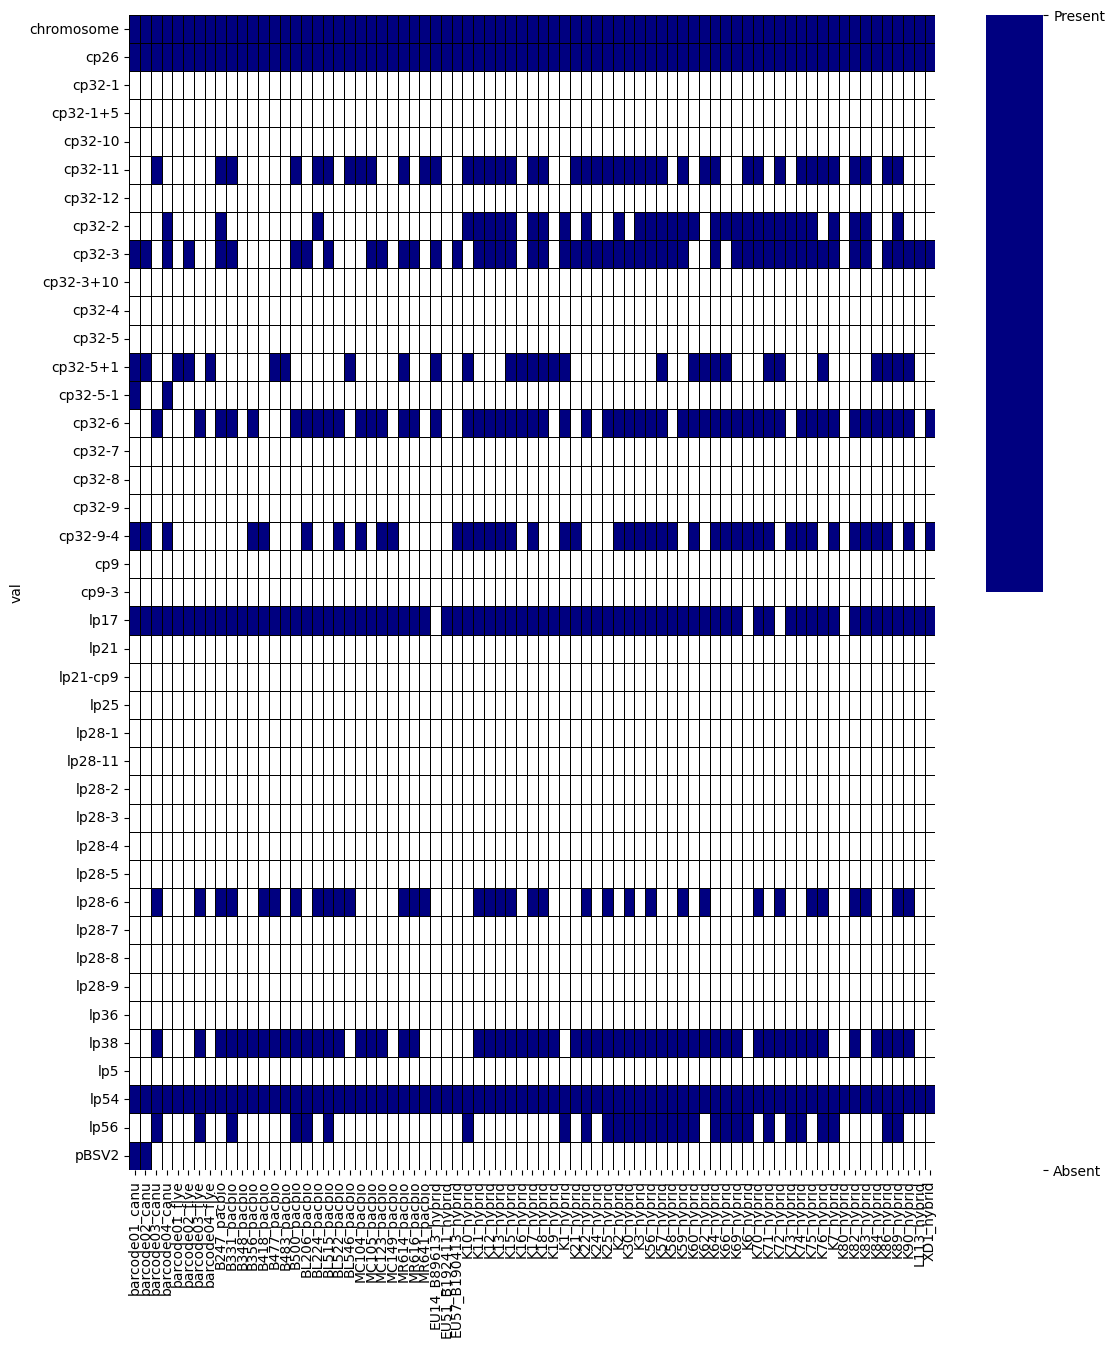

In [ ]:
plt.figure(figsize=(13,15))
cmap = sns.color_palette("blend:White,Navy",2)
barcode_matrix = sns.heatmap(uniq_plasmid_matrix_bool, linewidths=0.5, linecolor='black', cmap=cmap, xticklabels=True, yticklabels=True, )
colorbar = barcode_matrix.collections[0].colorbar
colorbar.set_ticks([0, 1])
colorbar.set_ticklabels(['Absent', 'Present',])
matrix.set_ylabel("Plasmid")
matrix.set_xlabel("Strain")
matrix.set_title("Borrelia burgdorferi Plasmid Presence and Absence by Strain")
plt.savefig(output_plots+"/barcode_plasmid_heatmap_all.png", dpi=300,bbox_inches='tight') # this was changed for addition of pacbio and hybrid assembly data

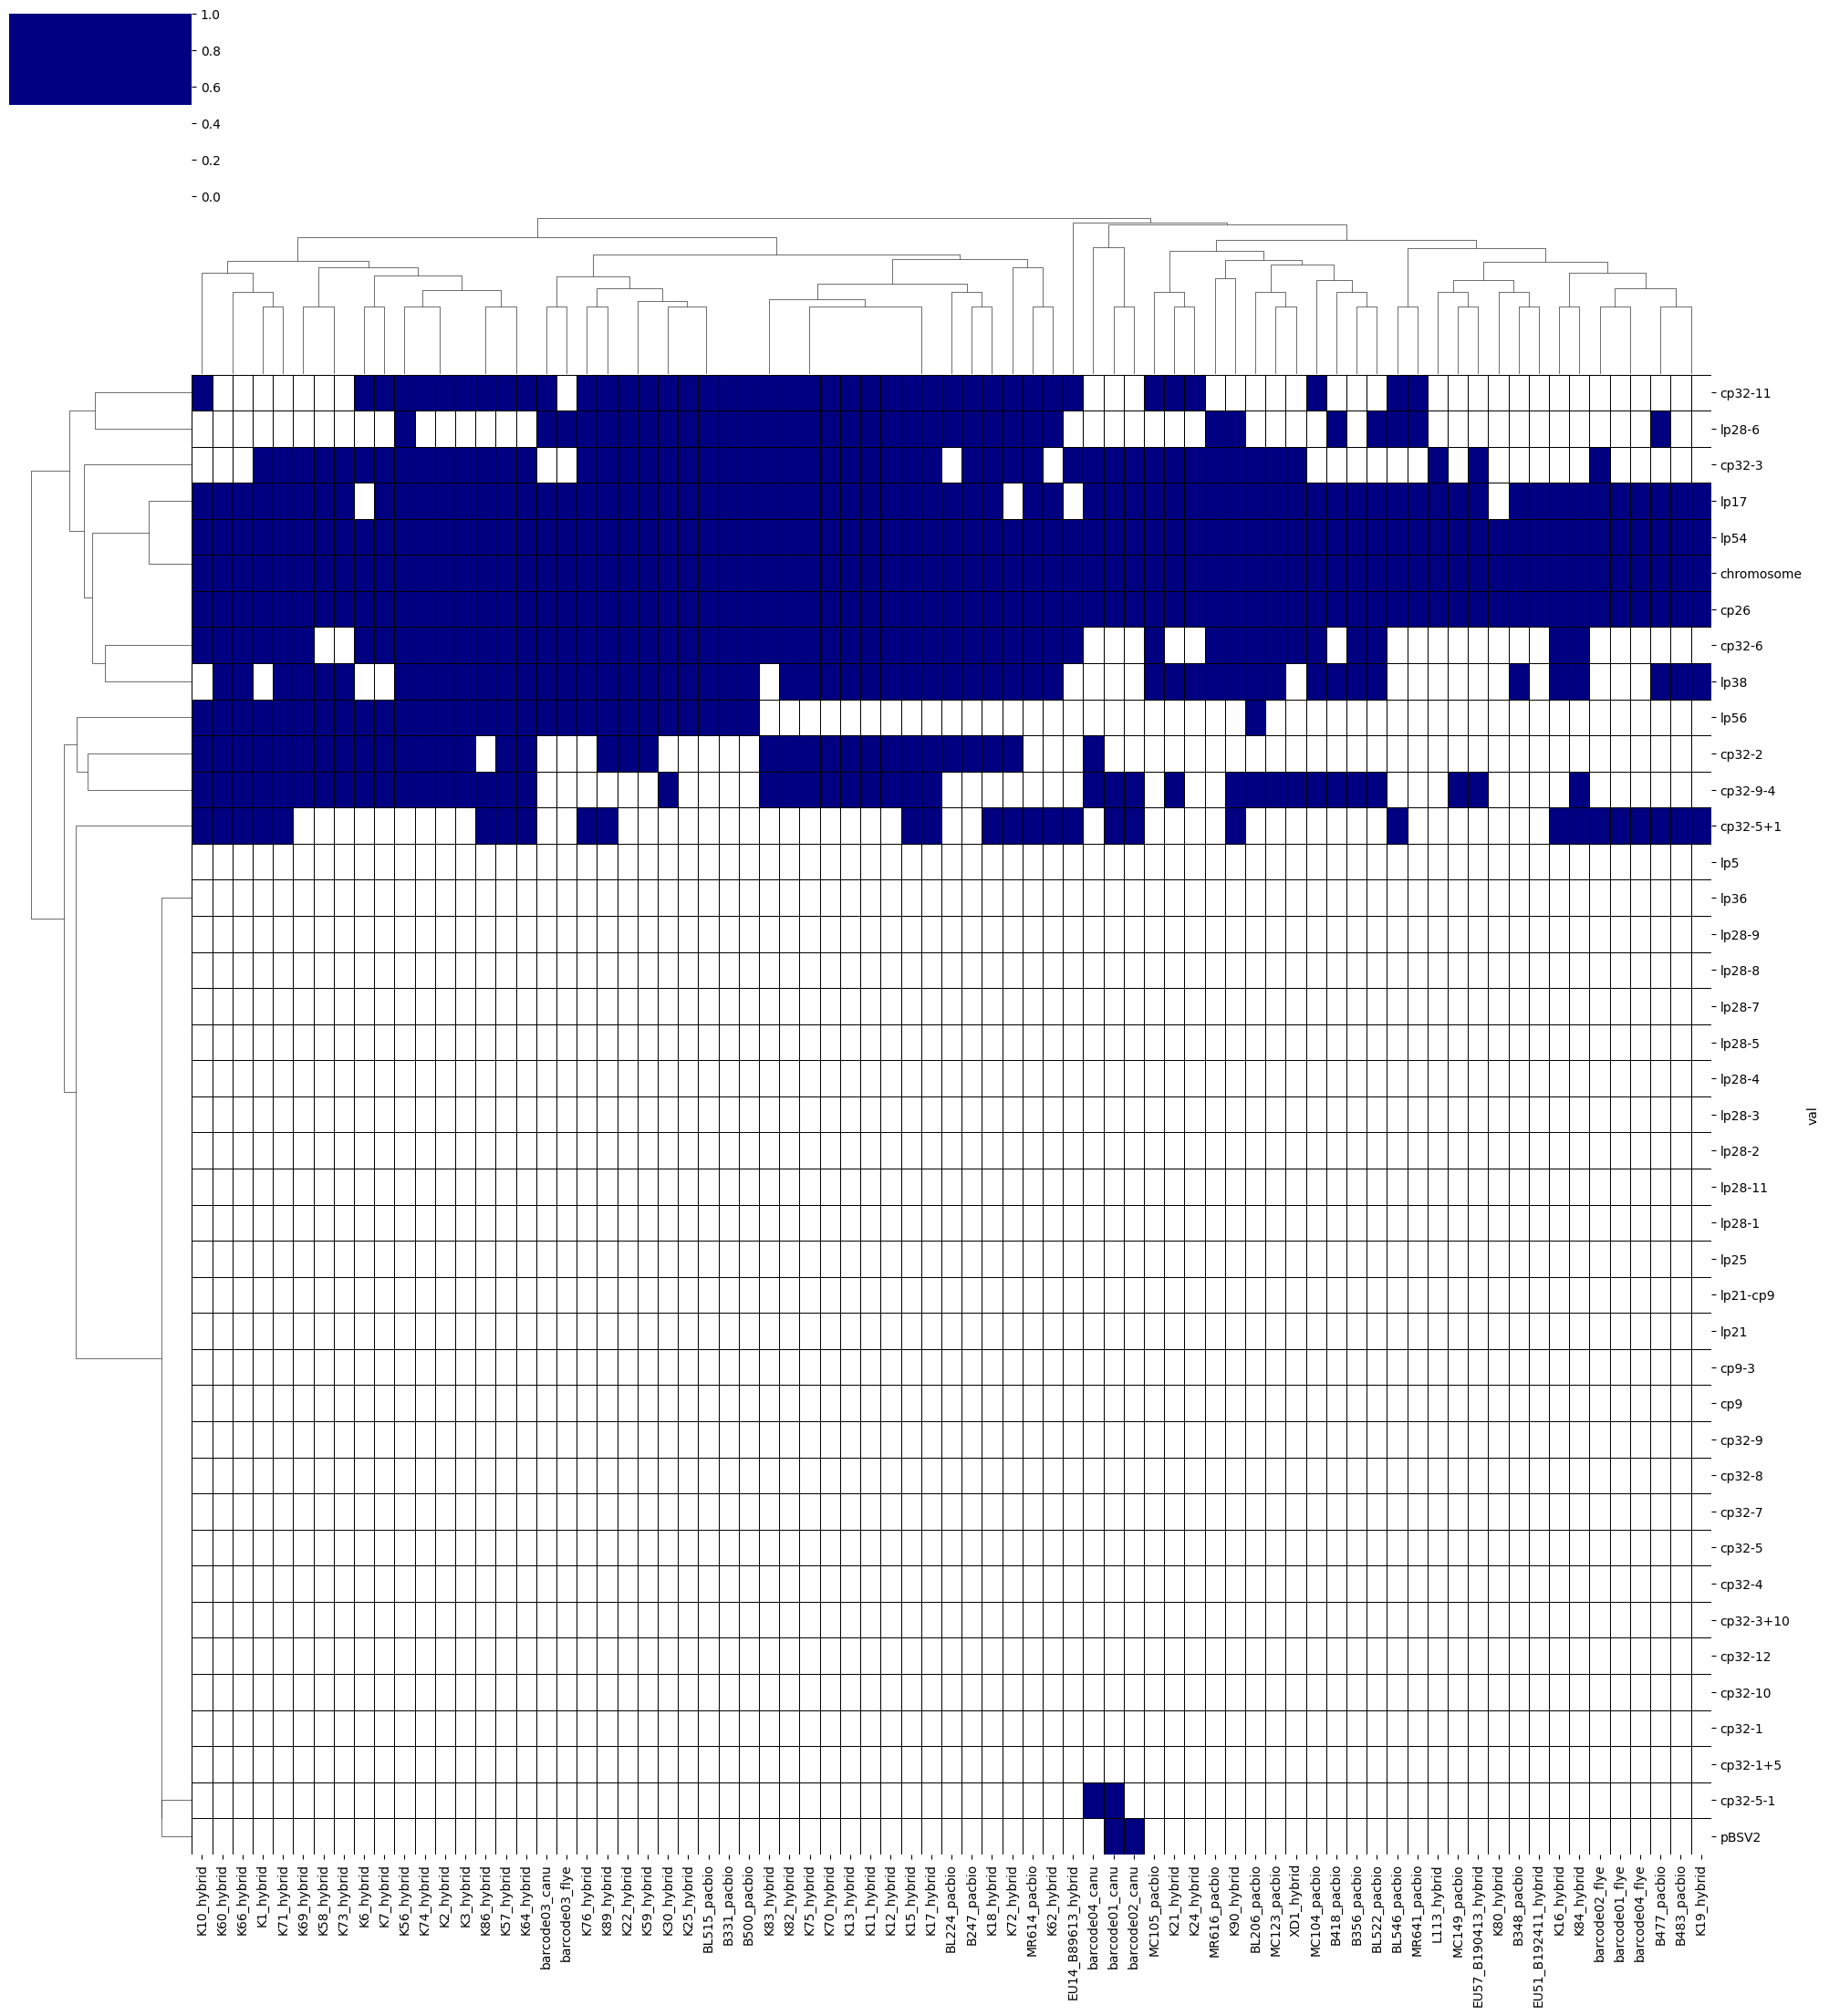

In [ ]:
barcode_matrix_cluster = sns.clustermap(uniq_plasmid_matrix_bool, figsize = (20,20), 
                        dendrogram_ratio = 0.1, metric='minkowski', 
                        cmap=cmap, linewidths=0.5, linecolor='black',
                        cbar_pos=(0, 1,0.1,0.1))
colorbar.set_ticks([0, 1])
colorbar.set_ticklabels(['Absent', 'Present',])

plt.savefig(output_plots+"/barcode_plasmid_heatmap_clustering_all.png", dpi=500, bbox_inches='tight')

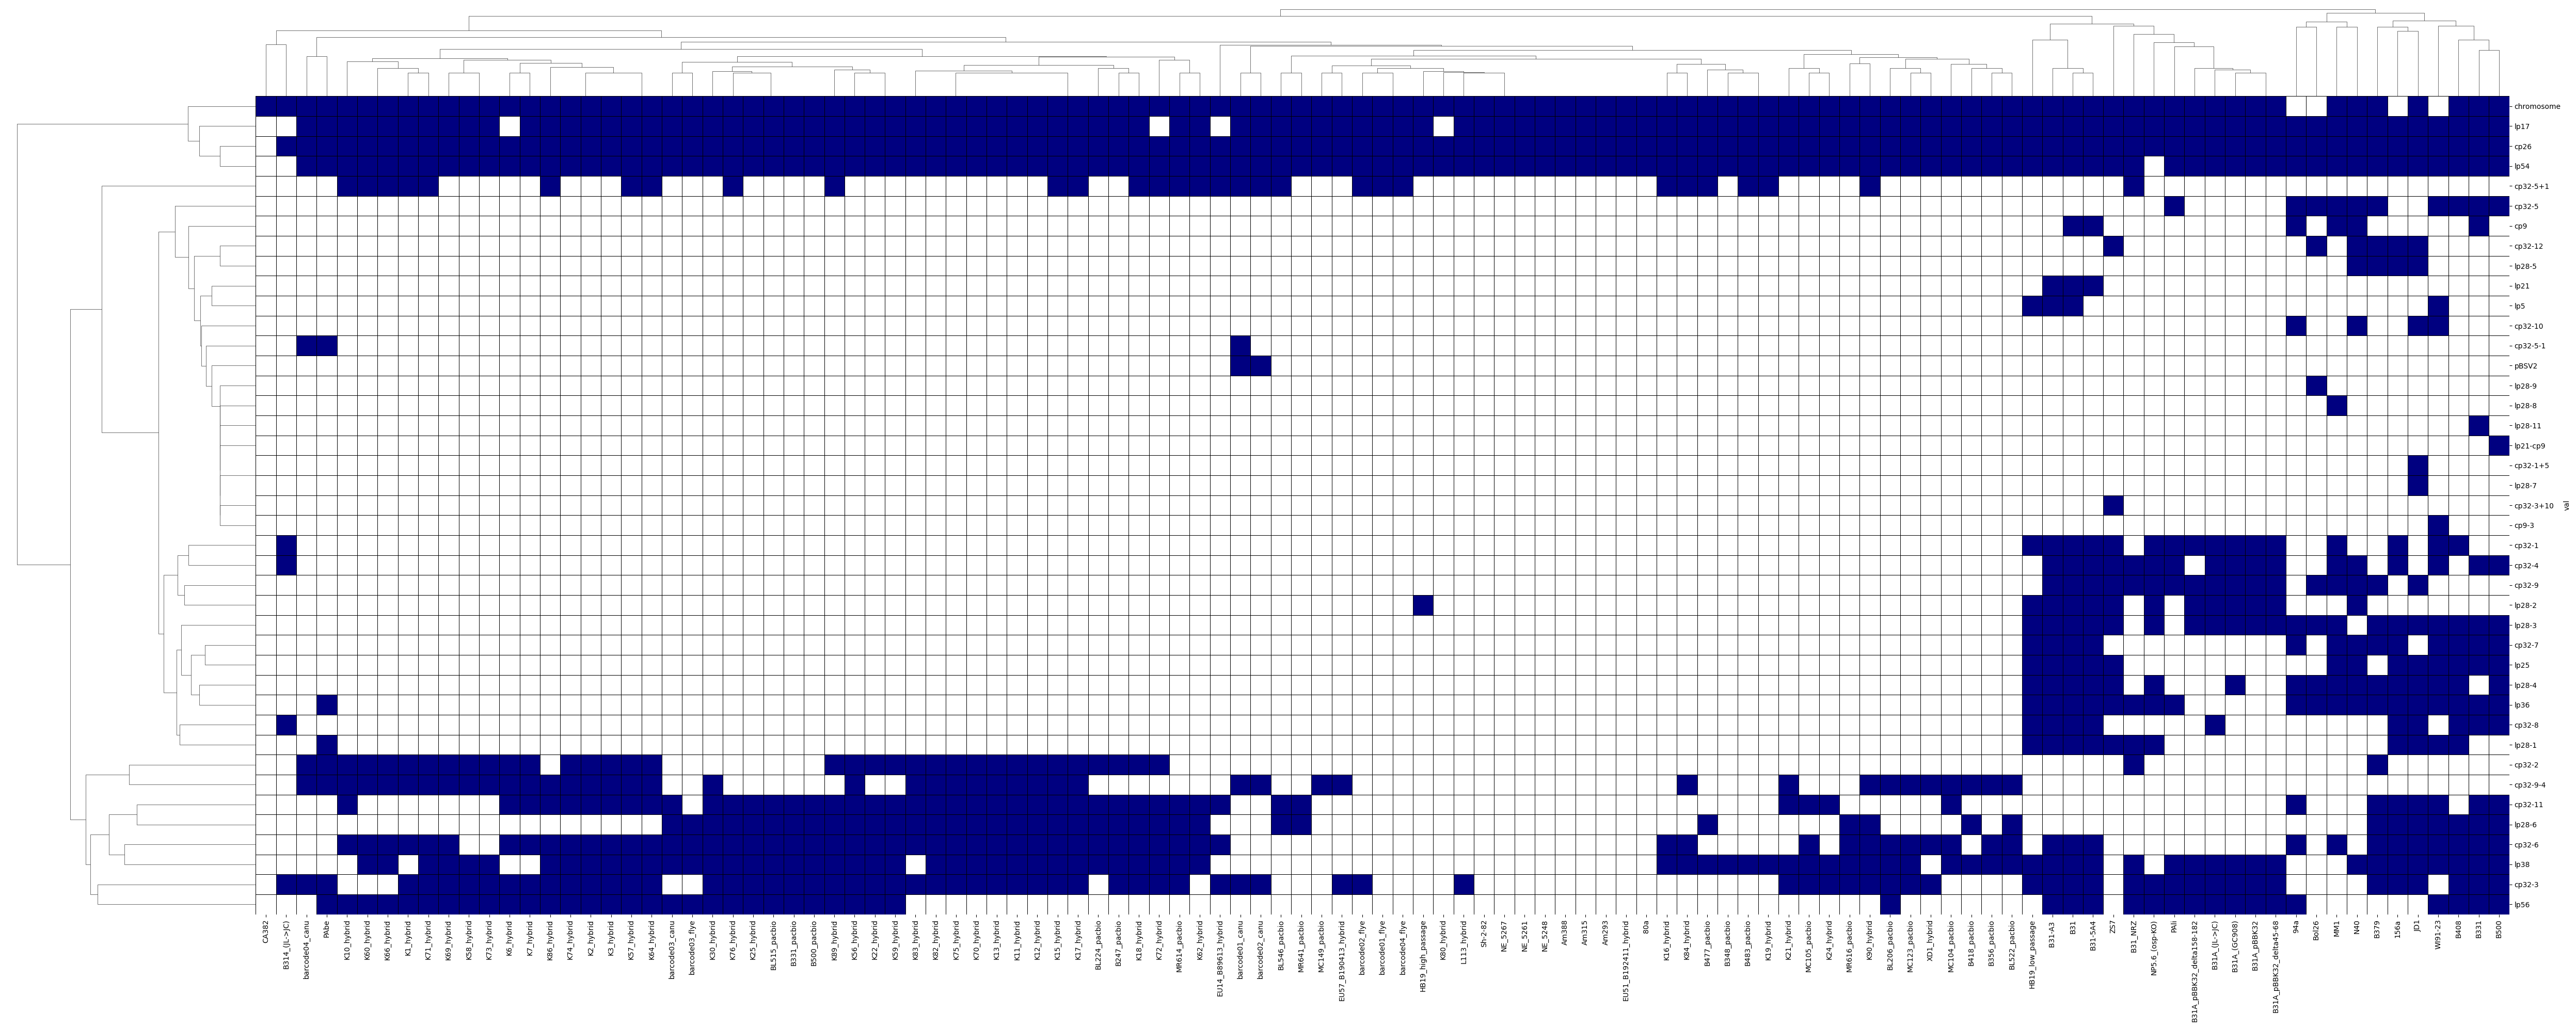

In [ ]:
barcode_matrix_cluster = sns.clustermap(merged_table_all, figsize = (50,20), 
                        dendrogram_ratio = 0.1,  metric='euclidean', 
                        cmap=cmap, linewidths=0.5, linecolor='black',
                        cbar_pos=None, row_cluster=True)


In [ ]:
plt.savefig(output_plots+"/BbPlasmidMatrixAllStrains.png", dpi=500, bbox_inches='tight')

# combined heatmap

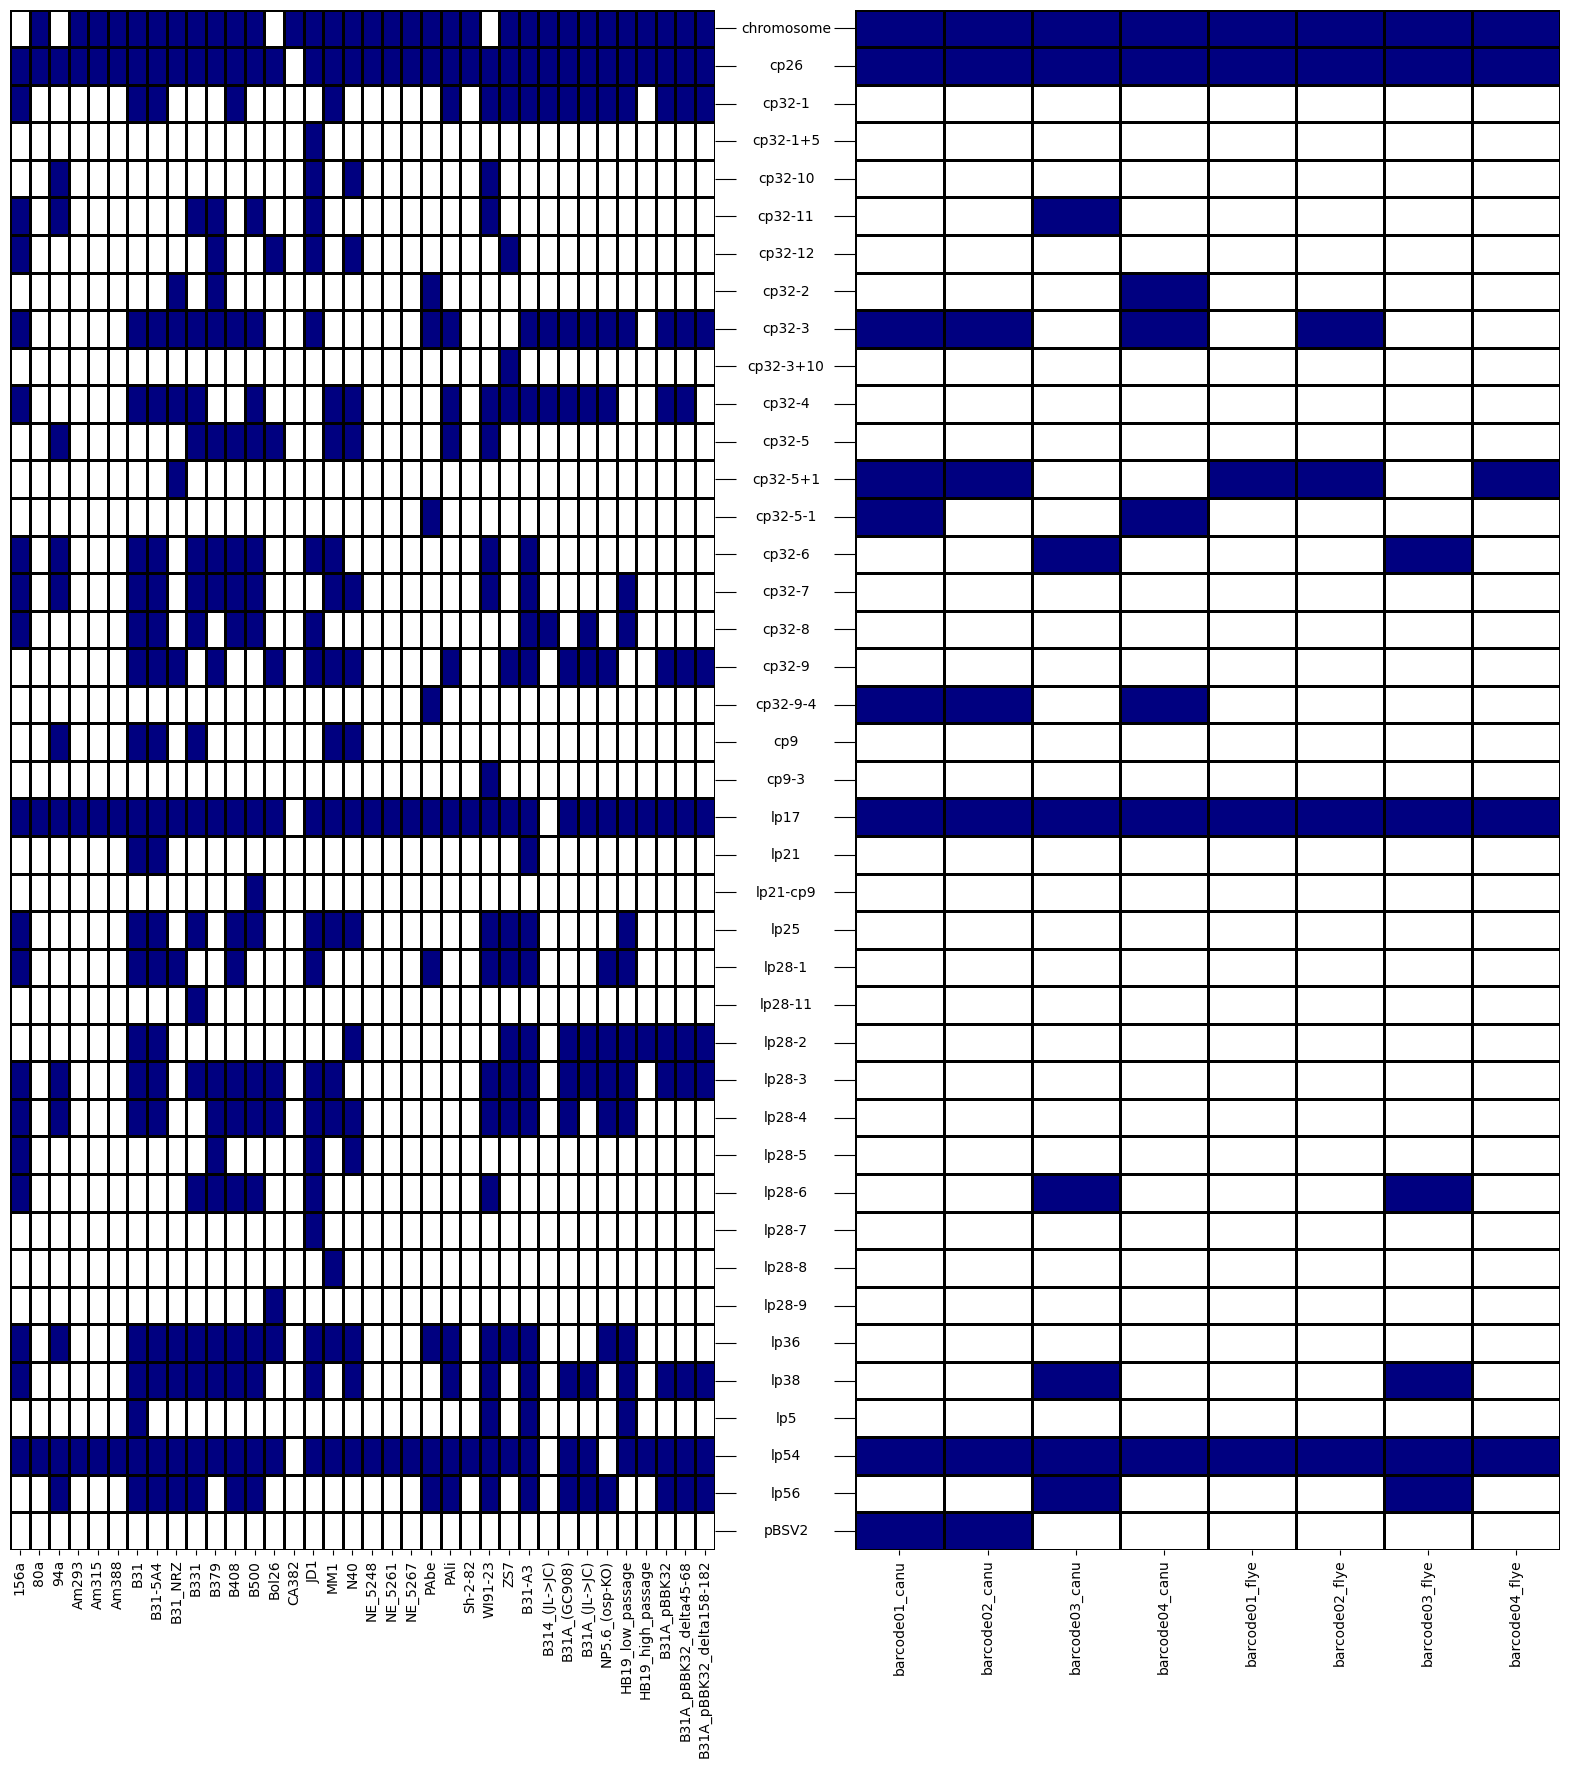

In [ ]:



import matplotlib.transforms


fig, ax = plt.subplots(1,2,figsize=(20,20))

cmap = sns.color_palette("blend:White,Navy",2)
matrix = sns.heatmap(merged_table, linewidths=0.75, linecolor='black', cmap=cmap, xticklabels=True, yticklabels=True, ax=ax[0],cbar=False)
barcode_matrix = sns.heatmap(uniq_plasmid_matrix_bool, linewidths=.75, linecolor='black', cmap=cmap, xticklabels=True,yticklabels=True,ax=ax[1],cbar=False)
ax[0].yaxis.set_tick_params(labelleft=False)
ax[1].yaxis.set_tick_params(labelleft=True)
ax[0].sharey(ax[1])

ax[1].set_yticklabels(uniq_plasmid_matrix_bool.index.values.tolist(), ha='center')
ax[1].tick_params('y', labelsize=10)
dx = 44/72.; dy = 0/72.
offset = matplotlib.transforms.ScaledTranslation(dx, dy, fig.dpi_scale_trans)

ax[0].axes.tick_params(axis='y', length=15)
ax[1].axes.tick_params(axis='y',length=15, pad = 35)
ax[0].yaxis.tick_right()
ax[0].set_ylabel("")
ax[1].set_ylabel("")
plt.savefig(output_plots+"/barcodes_vs_all_strains_heatmap.png", dpi=500)
plt.show()

# Lets Identify our Samples!

In [ ]:
# This is placeholder for the sample ID functions.